# IFC2 예측 GNN: 모든 코드를 담은 한국어 실습 노트북

**목표:** 원자 종류·위치·격자 → equivariant GNN → 3×3 IFC2 → Phonopy 포논까지 직접 따라갑니다.

이 파일에는 데이터 처리, 모델, loss, 학습, checkpoint, 추론, 물리 검증, ablation,
CLI와 Zenodo helper의 구현이 코드 셀에 직접 들어 있습니다. 별도 `ifc2` 패키지나 저장소 clone이 필요하지 않습니다.
PyTorch/e3nn/ASE/Phonopy 같은 외부 라이브러리는 필요합니다.

**처음 사용할 때:** Python 3.12 이상인 JupyterLab 또는 Colab에서 위에서부터 순서대로 실행하세요.
이미 저장된 출력은 이번 CPU 실행 결과이며, 설정을 바꿨다면 **Kernel Restart → Run All**로 다시 계산하세요.
실행마다 새 폴더를 만들므로 예전 checkpoint와 새 결과가 섞이지 않습니다.

기본 실습은 **합성 harmonic 데이터**를 사용합니다. DFT 결과나 universal 정확도·연구 신규성을 입증한 것이 아닙니다.
실제 데이터는 18절에서 별도 경로를 지정합니다. 제공된 Zenodo 기록은 이전 클라우드에서 proxy 403으로 접근되지 않았습니다.

### 읽는 순서

1. [환경과 기본 개념](#start)
2. [FC 분해·물리 제약·D(q)](#physics)
3. [주기 구조·compact FC 매핑](#data)
4. [GNN 연산과 persistent pair](#model)
5. [합성 데이터·loss·학습·추론 코드](#workflow)
6. [17개 자동화 테스트](#tests)
7. [실제 실행: shape → 학습 → 예측 → 그래프 → ablation](#run)
8. [실제 데이터·CLI·다운로드·제약](#real)

> 설명 셀을 먼저 읽고 바로 아래 함수를 따라가세요. 기호의 뜻을 잊으면 shape 표로 돌아오면 됩니다.

<a id="start"></a>
## 1. 의존성 준비 — 노트북 파일만으로 시작하기

아래 셀은 **없는 라이브러리만** 설치합니다. 설치된 PyTorch는 유지하여 CUDA 환경을 임의로 CPU 버전으로 바꾸지 않습니다.
PyTorch가 없다면 CPU wheel을 설치합니다. GPU 학습을 원하면 본인의 CUDA에 맞는 PyTorch를 먼저 설치하세요.

검증에 사용한 버전은 PyTorch 2.14.1+cpu / e3nn 0.6.0 / Phonopy 4.8.5 / ASE 3.29.0입니다.
이미 설치된 버전이 다르면 실행 결과의 version table을 확인하세요. 특히 Phonopy API 차이로 실패한다면 표시한 검증 버전을 설치하고 kernel을 재시작하세요.
`INSTALL_MISSING=False`로 바꾸면 자동 설치 대신 필요한 패키지를 알려주고 중단합니다.

In [2]:
import sys
import subprocess
import importlib.util
from importlib.metadata import version

if sys.version_info < (3, 12):
    raise RuntimeError("Python 3.12 이상 kernel을 선택해 주세요.")
INSTALL_MISSING = True
REQUIRED = {
    "numpy": "numpy==2.5.4",
    "e3nn": "e3nn==0.6.0",
    "ase": "ase==3.29.0",
    "phonopy": "phonopy==4.8.5",
    "matplotlib": "matplotlib==3.11.2",
    "yaml": "pyyaml==6.0.3",
    "pytest": "pytest==9.1.1",
}
if importlib.util.find_spec("torch") is None:
    if not INSTALL_MISSING:
        raise RuntimeError("현재 kernel에 PyTorch를 설치해 주세요.")
    subprocess.check_call(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "torch==2.14.1+cpu",
            "--index-url",
            "https://download.pytorch.org/whl/cpu",
        ]
    )
missing = [
    spec for module, spec in REQUIRED.items() if importlib.util.find_spec(module) is None
]
if missing:
    if not INSTALL_MISSING:
        raise RuntimeError(f"현재 kernel에 설치할 패키지: {missing}")
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
print("사용 Python:", sys.executable)
for package in ["torch", "e3nn", "phonopy", "ase", "numpy", "matplotlib", "pytest"]:
    print(f"{package:12s} {version(package)}")


사용 Python: /workspace/ifc2-env/bin/python
torch        2.14.1+cpu
e3nn         0.6.0
phonopy      4.8.5
ase          3.29.0
numpy        2.5.4
matplotlib   3.11.2
pytest       9.1.1


## 2. 공통 import와 재현성

모든 구현이 같은 notebook namespace를 사용합니다. 아래 import는 외부 라이브러리이며 프로젝트 내부 import는 없습니다.
float64는 작은 대칭성 오차를 확인하기 위한 선택입니다. GPU float32 성능은 별도 검증해야 합니다.
학습·예측은 CPU 기본값이고, 그림은 notebook 안에 표시합니다.

In [3]:
from pathlib import Path
from dataclasses import dataclass, asdict
from functools import lru_cache
from tempfile import TemporaryDirectory
from datetime import datetime, timezone
from uuid import uuid4
import os
import argparse
import copy
import csv
import hashlib
import json
import math
import time
import urllib.request

# 쓰기 가능한 캐시 경로: 읽기 전용 HOME인 클라우드에서도 matplotlib이 동작합니다.
os.environ.setdefault(
    "MPLCONFIGDIR", str(Path.cwd() / ".ifc2_notebook_cache" / "matplotlib")
)
os.environ.setdefault("XDG_CACHE_HOME", str(Path.cwd() / ".ifc2_notebook_cache"))

import numpy as np
import torch
from torch import nn
from e3nn import o3
from e3nn.io import CartesianTensor
from ase import Atoms
from ase.neighborlist import neighbor_list
import phonopy
from phonopy import Phonopy
from phonopy.structure.atoms import PhonopyAtoms
from phonopy.file_IO import write_FORCE_CONSTANTS
import pytest
import yaml
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

get_ipython().run_line_magic("matplotlib", "inline")
torch.set_default_dtype(torch.float64)
torch.set_num_threads(1)
torch.manual_seed(17)
np.random.seed(17)
print("CUDA 사용 가능:", torch.cuda.is_available())
print("기본 dtype:", torch.get_default_dtype())


CUDA 사용 가능: False
기본 dtype: torch.float64


## 3. 무엇을 예측하는가? — 에너지 곡률과 IFC2

$$\Phi_{ij}^{\alpha\beta}(R)
=\frac{\partial^2 E}{\partial u_i^\alpha(0)\partial u_j^\beta(R)}
=-\frac{\partial F_i^\alpha(0)}{\partial u_j^\beta(R)}.$$

쉽게 말하면 **j 원자를 β 방향으로 조금 밀었을 때 i 원자의 α 방향 힘이 얼마나 변하는가**입니다.
하나의 pair에는 α,β가 각각 x/y/z라서 9개 숫자가 필요합니다. 단위는 eV/Å²입니다.

- 회전/반전: $\Phi' = Q\Phi Q^T$.
- Hessian reciprocity: $\Phi_{ij}(R)=\Phi_{ji}(-R)^T$.
- Acoustic sum rule(ASR): $\sum_{j,R}\Phi_{ij}(R)=0$ — 결정 전체를 함께 이동해도 복원력이 생기지 않아야 합니다.
- 좌표 회전 등변성과 실제 강체 회전에 대한 rotational sum rule은 서로 다른 조건입니다. 후자는 이 구현에서 강제하지 않습니다.

### shape 사전

| 기호 | 의미 | 주요 tensor |
|---|---|---|
| N | primitive 원자 수 | z[N], positions[N,3], node[N,d] |
| Ns | supercell 원자 수 | compact FC[N,Ns,3,3] |
| E | convolution graph image 수 | conv_index[2,E], conv_vectors[E,3] |
| P | offsite compact label group 수 | pair_index[2,P], group FC[P,3,3] |
| M | 모든 shortest image 수 | pair_vectors[M,3], image_owner[M], image FC[M,3,3] |
| K / L | radial basis 수 / 최대 SH 차수 | radial[E,K], Y[E,(L+1)²] |
| Q | q-point 개수 | D[Q,3N,3N], frequencies[Q,3N] |

**P와 M를 구별하세요:** compact label 하나에 동등한 shortest image가 여러 개 있을 수 있습니다.
이미지별 IFC의 합은 compact label과 맞출 수 있지만, label만으로 각 image의 분배는 유일하게 식별되지 않습니다.

<a id="physics"></a>
## 4. FC 분해, 물리 제약과 Dynamical Matrix

3×3 tensor는 0e(1)+1e(3)+2e(5)의 총 9성분으로 분해합니다. 1e는 axial 성분이므로 반전에 부호가 바뀌지 않습니다. 다음 함수들은 모델과 독립적으로 선형대수/물리 계약을 구현합니다.

### `_basis`

e3nn의 CartesianTensor('ij')로 9개의 직교 기저 행렬을 만듭니다. 각 기저는 3×3이며 전체 shape는 [9,3,3]입니다. float64로 CG 계수를 만들어 작은 회전 오차를 줄이고, lru_cache로 한 번 계산한 결과를 재사용합니다.

In [4]:
@lru_cache(None)
def _basis():
    # e3nn constructs its CG constants in the default dtype.
    old = torch.get_default_dtype()
    try:
        torch.set_default_dtype(torch.float64)
        return CartesianTensor("ij").to_cartesian(torch.eye(9))
    finally:
        torch.set_default_dtype(old)


### `decompose`

FC[...,3,3]를 coefficient[...,9]로 변환합니다. 앞 1개는 0e(등방적 trace), 다음 3개는 1e(반대칭), 마지막 5개는 2e(대칭·무흔적)입니다. einsum의 ij는 Cartesian 축, k는 기저 번호입니다. 원소별 임의 학습 대신 회전 법칙이 정해진 채널로 나누는 준비 과정입니다.

In [5]:
def decompose(fc):
    """[...,3,3] -> [...,9], orthonormal 0e (1), 1e (3), 2e (5)."""
    return torch.einsum("...ij,kij->...k", fc, _basis().to(fc))


### `reconstruct`

9개 irrep coefficient를 같은 직교 기저에 곱해 FC[...,3,3]로 복원합니다. '분해 → 복원'은 정보 손실이 없어야 하며 뒤의 테스트에서 수치 오차를 검사합니다.

In [6]:
def reconstruct(coeff):
    return torch.einsum("...k,kij->...ij", coeff, _basis().to(coeff))


### `scatter`

값이 belongs-to index로 가리키는 그룹에 합산됩니다. values[E,d], index[E], size=N이면 결과는 [N,d]입니다. 여기서는 메시지를 원자별로 모으거나 image를 compact pair별로 모을 때 같은 연산을 사용합니다. index_add는 values에 대한 gradient를 보존합니다.

In [7]:
def scatter(values, index, size):
    return values.new_zeros((size,) + values.shape[1:]).index_add(0, index, values)


### `constrain_pairs`

raw[P,3,3]에서 먼저 역방향 tensor의 transpose와 평균하여 reciprocity를 맞춥니다. 하지만 그것만으로 onsite가 대칭이 되지는 않습니다. 반대칭 행합 d_i를 구한 뒤 graph Laplacian L의 의사역행렬로 v=L⁺d를 구하고, edge마다 v_i−v_j를 빼서 반대칭 행합을 0으로 만듭니다. cycle을 따라 흐르는 1e는 살아 있으므로 모든 FC를 대칭으로 만드는 연산이 아닙니다. L⁺는 구조에서 미리 계산되며 현재 dense O(N³) 전처리라 큰 primitive cell에는 sparse 구현이 필요합니다.

In [8]:
def constrain_pairs(raw, sample):
    """[P,3,3] -> reciprocal pairs with divergence-free antisymmetric part.

    After transpose reciprocity, project skew parts with the graph Laplacian.
    This preserves nonzero cycle-space 1e channels, then allows symmetric ASR onsite.
    Geometry-only pseudoinverse is precomputed by the data loader.
    """
    i, j = sample["pair_index"]
    # 정방향과 역방향의 transpose를 평균: 전체 Hessian의 reciprocity 조건입니다.
    x = (raw + raw[sample["reverse"]].transpose(-1, -2)) / 2
    # 각 3×3 block의 반대칭 부분만 추출합니다. 이것이 1e에 해당합니다.
    skew = (x - x.transpose(-1, -2)) / 2
    # 중심 원자별 반대칭 행합 [N,3,3]. 이것이 0이어야 onsite가 대칭입니다.
    divergence = scatter(skew, i, len(sample["z"]))
    # Cartesian 9성분에 같은 graph 연산 L⁺를 적용하여 등변성을 보존합니다.
    potential = (
        sample["laplacian_pinv"].to(raw) @ divergence.reshape(len(sample["z"]), 9)
    ).reshape(-1, 3, 3)
    return x - (potential[i] - potential[j])


### `compact_from_pairs`

예측한 offsite pair[P,3,3]를 compact FC[N,Nsuper,3,3]의 올바른 (i,supercell_j)에 배치합니다. onsite를 −Σ_offsite FC로 정하면 ASR가 성립합니다. 앞 단계에서 반대칭 행합을 제거했기 때문에 onsite symmetry도 함께 성립합니다. cutoff 밖 FC는 0으로 놓는 근사입니다.

In [9]:
def compact_from_pairs(pairs, sample):
    n, ns = len(sample["z"]), sample["n_super"]
    i = sample["pair_index"][0]
    ids = i * ns + sample["pair_super"]
    fc = scatter(pairs, ids, n * ns).reshape(n, ns, 3, 3)
    # offsite 합의 음수로 onsite를 정하면 행합 0, 즉 ASR가 성립합니다.
    onsite = -fc.sum(1)
    onsite_ids = torch.arange(n, device=pairs.device) * ns + sample["p2s"]
    return (fc.reshape(n * ns, 3, 3) + scatter(onsite, onsite_ids, n * ns)).reshape(
        n, ns, 3, 3
    )


### `dynamical_matrix`

FC에 Bloch phase exp(+2π i q·v)를 곱하고 sqrt(m_i m_j)로 나눠 D[Q,3N,3N]를 만듭니다. q와 v는 각각 primitive reciprocal/fractional 좌표입니다. 하나의 compact label에 shortest vector가 여러 개이면 phase를 평균합니다. complex tensor의 실수부·허수부에 PyTorch gradient가 흐릅니다. 이 함수에는 (D+D†)/2 보정이 없습니다. 그래야 잘못된 FC 때문에 생긴 non-Hermiticity를 발견할 수 있습니다.

In [10]:
def dynamical_matrix(fc, sample, q):
    """Raw complex D[Q,3N,3N], eV/Angstrom^2/amu. NO Hermitian repair.

    Phonopy atomic-position gauge: exp(+2pi i q dot shortest_fractional).
    Compact FC labels multiply the mean phase across ALL shortest images.
    """
    n, ns = fc.shape[:2]
    owner = sample["dm_owner"]
    # primitive fractional displacement와 reciprocal q의 내적: radian phase.
    angles = 2 * torch.pi * q @ sample["dm_vectors"].T
    # 실수 cos + 허수 i sin을 함께 유지합니다.
    phase_images = torch.exp(1j * angles).T
    phase = scatter(phase_images, owner, n * ns).T / sample["dm_count"][None, :]
    i = torch.arange(n, device=fc.device).repeat_interleave(ns)
    j = sample["s2p"].repeat(n)
    # 질량 가중치가 다르면 같은 FC라도 진동 주파수가 달라집니다.
    mass = torch.sqrt(sample["masses"][i] * sample["masses"][j])
    values = (
        phase[:, :, None, None] * fc.reshape(1, n * ns, 3, 3) / mass[None, :, None, None]
    )
    blocks = values.new_zeros((len(q), n * n, 3, 3)).index_add(1, i * n + j, values)
    return blocks.reshape(-1, n, n, 3, 3).permute(0, 1, 3, 2, 4).reshape(-1, 3 * n, 3 * n)


### `frequencies`

Hermiticity를 먼저 확인한 뒤 eigenvalue λ를 구합니다. signed frequency=sign(λ) sqrt(|λ|)×Phonopy 변환상수이며 음수로 표시한 주파수는 imaginary mode 진단입니다. Gamma 부근 sqrt의 gradient가 불안정할 수 있어 학습 loss에는 이 함수 대신 eigenvalue를 사용합니다.

In [11]:
def frequencies(dm, factor):
    error = (dm - dm.mH).abs().max()
    if error > 1e-7 * max(1.0, float(dm.abs().max().detach())):
        raise ValueError(f"Non-Hermitian dynamical matrix: {float(error.detach())}")
    eig = torch.linalg.eigvalsh(dm)
    return eig.sign() * eig.abs().sqrt() * factor


### `diagnostics`

reciprocity, ASR 행합, onsite 대칭성의 최대 절댓값 잔차를 반환합니다. 이 값들이 작다는 것은 해당 조건을 만족한다는 뜻이며 FC 정확도, 에너지 적분가능성, 모든 포논의 안정성을 의미하지는 않습니다.

In [12]:
def diagnostics(pairs, sample):
    fc = compact_from_pairs(pairs, sample)
    onsite = fc[torch.arange(len(fc), device=fc.device), sample["p2s"]]
    return {
        "reciprocity_error": float(
            (pairs - pairs[sample["reverse"]].transpose(-1, -2)).abs().max().detach()
        ),
        "asr_error": float(fc.sum(1).abs().max().detach()),
        "onsite_symmetry_error": float(
            (onsite - onsite.transpose(-1, -2)).abs().max().detach()
        ),
    }


### 손으로 확인하기: 임의 행렬을 분해하고 복원하기

대각합은 0e에, 비대칭은 1e에, trace를 뺀 대칭 방향성은 2e에 담깁니다.
정확한 coefficient 순서와 정규화는 e3nn의 기저를 따르므로 임의의 Cartesian 성분 순서로 해석하지 않습니다.

In [13]:
example_fc = torch.tensor([[2.0, 0.4, -0.2], [-0.1, 3.0, 0.5], [0.3, 0.2, 4.0]])
example_coeff = decompose(example_fc)
print("원래 FC:\n", example_fc)
for label, sl in [("0e", slice(0, 1)), ("1e", slice(1, 4)), ("2e", slice(4, 9))]:
    print(label, example_coeff[sl].tolist())
print("복원 최대 오차:", float((reconstruct(example_coeff) - example_fc).abs().max()))
torch.testing.assert_close(reconstruct(example_coeff), example_fc)


원래 FC:
 tensor([[ 2.0000,  0.4000, -0.2000],
        [-0.1000,  3.0000,  0.5000],
        [ 0.3000,  0.2000,  4.0000]])
0e [5.196152422706632]
1e [0.21213203435596423, 0.35355339059327373, 0.35355339059327373]
2e [0.07071067811865472, 0.21213203435596426, 2.220446049250313e-16, 0.49497474683058323, 1.4142135623730947]
복원 최대 오차: 4.440892098500626e-16


<a id="data"></a>
## 5. 데이터 로딩과 주기 graph

primitive→supercell 매핑을 원자번호 자체와 혼동하면 엉뚱한 FC를 학습합니다. 정답으로 graph를 만들지 않고 구조만으로 convolution graph와 target image를 따로 구성합니다. 아래 모든 shortest vector를 유지합니다.

### `shortest_vectors`

Phonopy가 제공하는 최단 주기 벡터를 [primitive_i][supercell_j][multiplicity,3] 형태의 리스트로 정리합니다. dense 주소/개수 포맷과 기존 배열 포맷을 명시적으로 처리하며, shape가 우연히 같다고 축을 추측해 뒤집지 않습니다.

In [14]:
def shortest_vectors(primitive):
    vectors, multi = primitive.get_smallest_vectors()
    ns, n = len(primitive.s2p_map), len(primitive)
    # Never guess transposition from shape: ns == n is ambiguous.
    if multi.shape == (ns, n, 2) and vectors.ndim == 2:
        return [
            [
                vectors[int(multi[s, i, 1]) : int(multi[s, i, 1] + multi[s, i, 0])]
                for s in range(ns)
            ]
            for i in range(n)
        ]
    if multi.shape == (ns, n) and vectors.ndim == 4:
        return [[vectors[s, i, : int(multi[s, i])] for s in range(ns)] for i in range(n)]
    raise ValueError(
        f"Unsupported Phonopy shortest-vector layout: {vectors.shape}, {multi.shape}"
    )


### `graph`

ASE neighbor_list로 cutoff 안의 모든 periodic image를 열거합니다. i는 메시지를 받는 중심 원자, j는 보내는 이웃입니다. r=x_j+shift@cell−x_i이며 graph index[2,E], vectors[E,3], shifts[E,3]를 반환합니다. force constant 정답은 입력으로 받지 않으므로 graph 생성에 label 누수가 없습니다.

In [15]:
def graph(z, positions, cell, cutoff, pbc=True):
    atoms = Atoms(
        numbers=np.asarray(z),
        positions=np.asarray(positions),
        cell=np.asarray(cell),
        pbc=pbc,
    )
    i, j, shift, vec = neighbor_list("ijSD", atoms, cutoff, self_interaction=False)
    keep = (np.linalg.norm(vec, axis=1) > 1e-8) & (np.linalg.norm(vec, axis=1) < cutoff)
    return (
        torch.tensor(np.stack([i[keep], j[keep]]), dtype=torch.long),
        torch.tensor(vec[keep], dtype=torch.float64),
        torch.tensor(shift[keep], dtype=torch.long),
    )


### `from_phonopy`

이 노트북의 데이터 계약을 만드는 핵심 함수입니다. p2s는 primitive 원자의 대표 supercell index, s2p는 각 supercell 원자의 primitive index입니다. convolution graph와 FC target pair를 별도로 만들고, shortest image의 owner 및 역방향 매핑을 구성합니다. labels가 있을 때만 target/target_compact를 붙이므로 모델에 전달되는 기하 정보는 정답 유무에 의존하지 않습니다. compact group P와 실제 image M를 혼동하지 않는 것이 중요합니다.

In [16]:
def from_phonopy(ph, conv_cutoff=4.5, pair_cutoff=5.5, material_id="structure"):
    p = ph.primitive
    n, ns = len(p), len(ph.supercell)
    # primitive 원자 i에 대응하는 대표 supercell 원자 번호입니다.
    p2s = np.asarray(p.p2s_map)
    representatives = {int(s): i for i, s in enumerate(p2s)}
    # 모든 supercell 원자를 primitive 번호 0..N−1로 되돌리는 mapping입니다.
    s2p = np.array([representatives[int(s)] for s in p.s2p_map])
    vectors = shortest_vectors(p)
    frac, cell = np.asarray(p.scaled_positions), np.asarray(p.cell)
    pi, pj, ps, image, owner, shifts = [], [], [], [], [], []
    dm_vec, dm_owner, dm_count = [], [], []
    for i in range(n):
        for s in range(ns):
            vf = np.asarray(vectors[i][s])
            if not len(vf):
                raise ValueError("Empty shortest-vector set")
            dm_vec.extend(vf)
            dm_owner.extend([i * ns + s] * len(vf))
            dm_count.append(len(vf))
            r = vf @ cell
            dist = np.linalg.norm(r, axis=1)
            if not np.allclose(dist, dist[0], atol=1e-6):
                raise ValueError("Unequal shortest distances")
            if s == p2s[i] and dist[0] < 1e-8:
                continue
            if dist[0] >= pair_cutoff:
                continue
            j = int(s2p[s])
            shift = vf - (frac[j] - frac[i])
            if not np.allclose(shift, np.rint(shift), atol=1e-6):
                raise ValueError("Noninteger primitive translation")
            # 여러 shortest image가 어느 compact label에 속하는지 잃지 않도록 저장합니다.
            owner.extend([len(pi)] * len(vf))
            image.extend(r)
            shifts.extend(np.rint(shift).astype(int))
            pi.append(i)
            pj.append(j)
            ps.append(s)
    if not pi:
        raise ValueError("No target pairs inside cutoff")
    owner = np.asarray(owner)
    shifts = np.asarray(shifts)
    keys = {}
    for k, (i, j) in enumerate(zip(pi, pj)):
        key = (i, j, tuple(sorted(map(tuple, shifts[owner == k]))))
        if key in keys:
            raise ValueError("Duplicate compact image group")
        keys[key] = k
    # 정방향 그룹 (i,j,{R})과 역방향 그룹 (j,i,{-R})를 연결합니다.
    reverse = []
    for k, (i, j) in enumerate(zip(pi, pj)):
        key = (j, i, tuple(sorted(map(tuple, -shifts[owner == k]))))
        if key not in keys:
            raise ValueError("Target graph is not closed under reversal")
        reverse.append(keys[key])
    # 그룹뿐 아니라 개별 periodic image의 역방향 index도 구성합니다.
    image_keys = {(pi[k], pj[k], tuple(shifts[t])): t for t, k in enumerate(owner)}
    image_reverse = [
        image_keys[(pj[k], pi[k], tuple(-shifts[t]))] for t, k in enumerate(owner)
    ]
    # 원자 사이 연결의 graph Laplacian. FC 정답값과 무관합니다.
    lap = np.zeros((n, n))
    for i, j in zip(pi, pj):
        lap[i, i] += 1
        lap[i, j] -= 1
    # 메시지용 convolution graph는 target pair graph와 별도로 만듭니다.
    ci, cv, cs = graph(p.numbers, p.positions, cell, conv_cutoff)
    f = lambda x: torch.tensor(np.asarray(x), dtype=torch.float64)
    l = lambda x: torch.tensor(np.asarray(x), dtype=torch.long)
    sample = dict(
        material_id=material_id,
        z=l(p.numbers),
        positions=f(p.positions),
        cell=f(cell),
        fractional=f(frac),
        masses=f(p.masses),
        p2s=l(p2s),
        s2p=l(s2p),
        n_super=ns,
        pair_index=l([pi, pj]),
        pair_super=l(ps),
        pair_vectors=f(image),
        image_owner=l(owner),
        pair_shift=l(shifts),
        reverse=l(reverse),
        laplacian_pinv=f(np.linalg.pinv(lap, hermitian=True)),
        image_reverse=l(image_reverse),
        conv_index=ci,
        conv_vectors=cv,
        conv_shift=cs,
        dm_vectors=f(dm_vec),
        dm_owner=l(dm_owner),
        dm_count=f(dm_count),
        frequency_factor=float(ph.unit_conversion_factor),
    )
    # 정답은 마지막에 별도 field로 붙입니다. 구조만의 추론도 같은 graph를 사용합니다.
    if ph.force_constants is not None:
        fc = np.asarray(ph.force_constants)
        if fc.shape[:2] == (ns, ns):
            fc = fc[p2s]
        if fc.shape != (n, ns, 3, 3):
            raise ValueError(f"Invalid FC shape: {fc.shape}")
        if not np.isfinite(fc).all():
            raise ValueError("Nonfinite FC")
        sample["target_compact"] = f(fc)
        sample["target"] = f(fc[np.asarray(pi), np.asarray(ps)])
    return sample


### `load_material`

폴더 안 phonopy.yaml과 FORCE_CONSTANTS를 읽고 full FC도 compact로 변환합니다. labels=False이면 예측에 사용할 구조만 반환합니다. nac=True일 때 BORN이 있으면 Phonopy에 전달하지만 GNN 자체가 Born charge나 dielectric을 예측하는 것은 아닙니다. 이 코드의 단위 계약은 Å, amu, eV/Å²입니다.

In [17]:
def load_material(path, conv_cutoff=4.5, pair_cutoff=5.5, nac=False, labels=True):
    path = Path(path)
    kwargs = dict(phonopy_yaml=str(path / "phonopy.yaml"), is_nac=nac, is_compact_fc=True)
    if labels:
        kwargs["force_constants_filename"] = str(path / "FORCE_CONSTANTS")
    if nac and (path / "BORN").exists():
        kwargs["born_filename"] = str(path / "BORN")
    ph = phonopy.load(**kwargs)
    if not labels:
        ph.force_constants = None
    return ph, from_phonopy(ph, conv_cutoff, pair_cutoff, path.name)


### `material_split`

pair가 아니라 재료 ID 단위로 train/validation/test를 나눕니다. 해시와 seed로 순서를 결정하므로 같은 ID 집합에 재현 가능한 결과를 줍니다. 같은 물질의 여러 변형 폴더는 자동으로 알아내지 못하므로 실제 연구에서는 parent material 기준 split을 직접 제공해야 합니다.

In [18]:
def material_split(ids, seed=17):
    if len(ids) != len(set(ids)):
        raise ValueError("Duplicate material identifiers")
    if len(ids) < 3:
        raise ValueError("At least three independent materials required")
    ordered = sorted(ids, key=lambda x: hashlib.sha256(f"{seed}:{x}".encode()).hexdigest())
    nv = max(1, len(ids) // 5)
    nt = max(1, len(ids) // 5)
    return dict(
        train=ordered[nv + nt :], validation=ordered[:nv], test=ordered[nv : nv + nt]
    )


### `to_device`

sample dictionary의 tensor만 CPU 또는 GPU로 옮기고 문자열·정수 metadata는 유지합니다. 정밀 대칭 검증은 float64 CPU에서 수행하며 CUDA는 선택 사항입니다.

In [19]:
def to_device(sample, device):
    return {
        k: v.to(device) if isinstance(v, torch.Tensor) else v for k, v in sample.items()
    }


<a id="model"></a>
## 6. GNN: geometry → node → persistent pair → IFC2

연산 흐름은 원소 embedding → 거리/방향 tensor product → 이웃 합·attention·고차 correlation → pair state 갱신 → 9성분 readout → 물리 projection입니다. 각 모듈을 독립적으로 바꾸어 실험할 수 있도록 구성했습니다.

### `ModelConfig`

모델을 바꾸는 설정을 한곳에 모은 dataclass입니다. width는 irrep copy 수, lmax는 기하 spherical harmonic 최대 차수, correlation은 1/2/3입니다. correlation=1은 추가 density product가 없다는 뜻입니다. independent_heads는 symmetric/skew backbone 분리, persistent_pair는 매 layer pair 갱신, enhanced_fusion은 pair와 최신 양 끝 원자 환경의 곱을 켭니다. sum_attention과 attention_only를 같은 구조에서 비교할 수 있습니다. 현재 hidden irreps도 lmax까지만 만들므로 완전한 0e/1e/2e FC 예측에는 lmax≥2를 사용하세요. lmax=1이면 2e readout에 연결되는 hidden 성분이 없습니다.

In [20]:
@dataclass
class ModelConfig:
    width: int = 4
    layers: int = 2
    lmax: int = 2
    num_rbf: int = 8
    conv_cutoff: float = 4.5
    pair_cutoff: float = 5.5
    correlation: int = 2
    attention: bool = True
    attention_heads: int = 2
    aggregation: str = "sum_attention"
    persistent_pair: bool = True
    enhanced_fusion: bool = False
    physics_residual: bool = False
    independent_heads: bool = False

    def __post_init__(self):
        if self.lmax < 1 or self.width < 1 or self.layers < 1:
            raise ValueError("Invalid model dimensions")
        if self.correlation not in (1, 2, 3):
            raise ValueError("correlation must be 1, 2 or 3")
        if self.aggregation not in ("sum_attention", "attention_only"):
            raise ValueError("Invalid aggregation")
        if self.attention_heads < 1 or min(self.conv_cutoff, self.pair_cutoff) <= 0:
            raise ValueError("Invalid heads/cutoff")


### `geometry`

거리 d에서 x=d/cutoff를 만들고, 끝에서 부드럽게 0이 되는 envelope=(1−x)^3(1+3x+6x²)를 씌웁니다. radial[E,K]는 sinc 기저, Y[E,(LMAX+1)²]는 방향 정보입니다. scalar radial은 회전해도 같고 Y는 각 l의 표현에 따라 변환하므로 두 정보를 tensor product로 결합할 수 있습니다.

In [21]:
def geometry(v, cutoff, num_rbf, lmax):
    distance = v.norm(dim=-1)
    x = distance / cutoff
    # cutoff 밖은 정확히 0입니다. 경계 안에서는 부드럽게 감쇠합니다.
    envelope = torch.where(
        x < 1, (1 - x).clamp_min(0) ** 3 * (1 + 3 * x + 6 * x * x), torch.zeros_like(x)
    )
    k = torch.arange(1, num_rbf + 1, device=v.device, dtype=v.dtype)
    # torch.sinc(x)=sin(πx)/(πx)이므로 0 근처도 수치적으로 안정적입니다.
    radial = torch.sinc(x[:, None] * k) * envelope[:, None]
    # 방향을 l별 irrep로 표현합니다. 회전 시 정해진 D^l(Q)로 변환됩니다.
    sh = o3.spherical_harmonics(
        list(range(lmax + 1)), v, normalize=True, normalization="component"
    )
    return radial, sh, envelope


### `InvariantGate`

일반 ReLU를 벡터의 x,y,z 성분에 각각 적용하면 회전 등변성이 깨질 수 있습니다. 대신 0e scalar로 sigmoid gate를 만들고 동일 irrep copy의 모든 m 성분에 같은 값을 곱합니다. scalar 부분에는 SiLU를 적용합니다. 입력과 출력은 모두 [N,d] 또는 [M,d]입니다.

In [22]:
class InvariantGate(nn.Module):
    def __init__(self, irreps, width):
        super().__init__()
        self.irreps = irreps
        self.width = width
        self.gate = nn.Linear(width, irreps.num_irreps - width)

    def forward(self, x):
        weights = torch.sigmoid(self.gate(x[:, : self.width]))
        pieces = [torch.nn.functional.silu(x[:, : self.width])]
        start = 0
        for (mul, ir), sl in list(zip(self.irreps, self.irreps.slices()))[1:]:
            pieces.append(
                (
                    x[:, sl].reshape(-1, mul, ir.dim)
                    * weights[:, start : start + mul, None]
                ).flatten(1)
            )
            start += mul
        return torch.cat(pieces, -1)


### `RadialTP`

m=TP(h,Y;w(r))입니다. e3nn FullyConnectedTensorProduct는 triangle rule과 parity에 허용된 Clebsch–Gordan 결합만 사용합니다. radial MLP가 edge별 coupling weight를 예측하므로 거리별 반응은 달라져도 변환 법칙은 유지됩니다. 입력 [E,d_in], [E,d_SH], [E,K] → [E,d_out]입니다.

In [23]:
class RadialTP(nn.Module):
    def __init__(self, ir, sh, out, rbf, width):
        super().__init__()
        # 허용된 angular momentum/parity coupling만 연결하는 equivariant 곱입니다.
        self.tp = o3.FullyConnectedTensorProduct(ir, sh, out, shared_weights=False)
        self.radial = nn.Sequential(
            nn.Linear(rbf, 2 * width), nn.SiLU(), nn.Linear(2 * width, self.tp.weight_numel)
        )

    def forward(self, x, sh, radial, envelope):
        return self.tp(x, sh, self.radial(radial)) * envelope[:, None]


### `Interaction`

이웃 메시지 합 A_i=Σ_j m_ij는 배위수 정보를 보존합니다. sum 경로와 invariant scalar score의 multi-head attention을 합칠 수 있고, TP(A,A), TP(TP(A,A),A)로 고차 환경 상관을 추가합니다. 이 재귀 projected TP는 MACE의 완전한 symmetric contraction과 동일한 구현은 아닙니다. cutoff 밖 edge를 softmax 전에 제외합니다. 1/sqrt(12)는 고정된 수치 크기 정규화이며 물리 상수나 실제 배위수를 뜻하지 않습니다. 현재 atom별 mask loop는 설명 가능한 작은 기준 구현이며 큰 구조에는 segmented softmax 최적화가 필요합니다.

In [24]:
class Interaction(nn.Module):
    def __init__(self, ir, c):
        super().__init__()
        self.c = c
        self.ir = ir
        self.message = RadialTP(
            ir, o3.Irreps.spherical_harmonics(c.lmax), ir, c.num_rbf, c.width
        )
        self.mix = o3.Linear(ir, ir)
        self.gate = InvariantGate(ir, c.width)
        if c.correlation > 1:
            # ACE-inspired recursive density products, not MACE's complete symmetric basis.
            # ν=2는 TP(A,A), ν=3은 한 번 더 A와 결합합니다. full MACE basis는 아닙니다.
            self.products = nn.ModuleList(
                [
                    o3.FullyConnectedTensorProduct(ir, ir, ir)
                    for _ in range(c.correlation - 1)
                ]
            )
        if c.attention:
            self.score = nn.Sequential(
                nn.Linear(2 * c.width + c.num_rbf, c.width),
                nn.SiLU(),
                nn.Linear(c.width, c.attention_heads),
            )
            self.values = nn.ModuleList(
                [o3.Linear(ir, ir) for _ in range(c.attention_heads)]
            )
            self.att_mix = o3.Linear(ir * c.attention_heads, ir)

    def forward(self, h, index, radial, sh, envelope):
        i, j = index
        n = len(h)
        # Remove outside-cutoff entries BEFORE attention normalization.
        # softmax 분모에 cutoff 밖 원자가 들어가지 않도록 먼저 제거합니다.
        active = envelope > 0
        i, j = i[active], j[active]
        radial, sh, envelope = radial[active], sh[active], envelope[active]
        m = self.message(h[j], sh, radial, envelope)
        # 합산은 이웃 수 정보도 담습니다. sqrt(12)는 고정 수치 정규화입니다.
        density = scatter(m, i, n) / math.sqrt(12.0)
        update = self.mix(density)
        if self.c.attention:
            # 0e scalar와 거리만으로 logit을 만들므로 O(3)-invariant입니다.
            scores = self.score(
                torch.cat([h[i, : self.c.width], h[j, : self.c.width], radial], -1)
            )
            attended = []
            for head, value_layer in enumerate(self.values):
                # Local segment softmax; small reference implementation, no torch_scatter dependency.
                rows = []
                values = value_layer(m)
                for atom in range(n):
                    mask = i == atom
                    if mask.any():
                        # log-envelope를 더하면 exp(score)에 envelope를 곱하는 가중이 됩니다.
                        logits = scores[mask, head] + torch.log(envelope[mask])
                        rows.append((logits.softmax(0)[:, None] * values[mask]).sum(0))
                    else:
                        rows.append(h.new_zeros(self.ir.dim))
                attended.append(torch.stack(rows))
            # head를 결합할 때도 o3.Linear로 같은 irrep끼리만 섞습니다.
            attention = self.att_mix(torch.cat(attended, -1))
            update = (
                attention if self.c.aggregation == "attention_only" else update + attention
            )
        if self.c.correlation > 1:
            product = density
            for tp in self.products:
                # 이웃 density끼리 결합하므로 서로 다른 이웃의 각도 상관을 표현할 수 있습니다.
                product = tp(product, density)
                update = update + product
        return h + self.gate(update) / math.sqrt(self.c.layers)


### `PairBackbone`

원자번호를 scalar로 embedding한 뒤 node layer를 진행합니다. 별도의 target image마다 pair state p[M,d]를 만들고 updated h_i,h_j와 함께 반복 갱신합니다. enhanced_fusion은 TP(p,Linear(h_i⊕h_j))로 이미 기억한 결합 환경과 새 node 정보를 곱합니다. 마지막 o3.Linear는 0e+1e+2e의 9성분을 읽고 Cartesian FC를 복원합니다. 선택적 stiffness head는 k_parallel uuᵀ+k_perp(I−uuᵀ)를 더하지만 noncentral 성분은 GNN residual에 남겨 둡니다.

In [25]:
class PairBackbone(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.c = c
        # Include both polar 1o and axial 1e. lmax controls geometric SH order.
        # 극벡터 1o와 축벡터 1e를 모두 포함합니다. 둘은 반전 parity가 다릅니다.
        self.ir = o3.Irreps(
            [(c.width, (0, 1))]
            + [(c.width, (l, p)) for l in range(1, c.lmax + 1) for p in (-1, 1)]
        )
        self.embedding = nn.Embedding(119, c.width)
        self.embed = o3.Linear(f"{c.width}x0e", self.ir)
        self.layers = nn.ModuleList([Interaction(self.ir, c) for _ in range(c.layers)])
        sh = o3.Irreps.spherical_harmonics(c.lmax)
        self.pair_init = RadialTP(self.ir + self.ir, sh, self.ir, c.num_rbf, c.width)
        self.pair_updates = nn.ModuleList(
            [
                RadialTP(self.ir + self.ir, sh, self.ir, c.num_rbf, c.width)
                for _ in range(c.layers if c.persistent_pair else 1)
            ]
        )
        self.pair_skips = nn.ModuleList(
            [o3.Linear(self.ir, self.ir) for _ in self.pair_updates]
        )
        self.pair_gates = nn.ModuleList(
            [InvariantGate(self.ir, c.width) for _ in self.pair_updates]
        )
        if c.enhanced_fusion:
            self.pair_context = o3.Linear(self.ir + self.ir, self.ir)
            self.pair_products = nn.ModuleList(
                [
                    o3.FullyConnectedTensorProduct(self.ir, self.ir, self.ir)
                    for _ in self.pair_updates
                ]
            )
        # scalar 1개 + antisymmetric 3개 + symmetric traceless 5개 = 총 9성분.
        self.readout = o3.Linear(self.ir, "0e+1e+2e")
        if c.physics_residual:
            self.stiffness = nn.Sequential(
                nn.Linear(2 * c.width + c.num_rbf, c.width),
                nn.SiLU(),
                nn.Linear(c.width, 2),
            )

    def forward(self, s):
        c = self.c
        h = self.embed(self.embedding(s["z"]))
        cg = geometry(s["conv_vectors"], c.conv_cutoff, c.num_rbf, c.lmax)
        pg = geometry(s["pair_vectors"], c.pair_cutoff, c.num_rbf, c.lmax)
        # M개의 image마다 primitive 양 끝 원자를 펼쳐서 가져옵니다.
        owners = s["image_owner"]
        i, j = s["pair_index"][:, owners]
        # target image의 초기 pair state [M,d]. convolution edge state와 다릅니다.
        pair = self.pair_init(torch.cat([h[i], h[j]], -1), pg[1], pg[0], pg[2])
        for layer, block in enumerate(self.layers):
            # 주변 원자들의 정보를 모아 node state를 갱신합니다.
            h = block(h, s["conv_index"], *cg)
            if c.persistent_pair:
                update = self.pair_updates[layer](
                    torch.cat([h[i], h[j]], -1), pg[1], pg[0], pg[2]
                )
                if c.enhanced_fusion:
                    # 기존 결합 상태와 새 환경의 곱: enhanced persistent pair fusion.
                    update = update + self.pair_products[layer](
                        pair, self.pair_context(torch.cat([h[i], h[j]], -1))
                    )
                pair = pair + self.pair_gates[layer](
                    self.pair_skips[layer](pair) + update
                ) / math.sqrt(c.layers)
        if not c.persistent_pair:
            pair = self.pair_gates[0](
                self.pair_skips[0](pair)
                + self.pair_updates[0](torch.cat([h[i], h[j]], -1), pg[1], pg[0], pg[2])
            )
        # 이 지점에서 처음으로 Cartesian 3×3 IFC2 tensor가 만들어집니다.
        images = reconstruct(self.readout(pair))
        if c.physics_residual:
            kl, kt = self.stiffness(
                torch.cat([h[i, : c.width], h[j, : c.width], pg[0]], -1)
            ).unbind(-1)
            unit = torch.nn.functional.normalize(s["pair_vectors"], dim=-1)
            outer = unit[:, :, None] * unit[:, None, :]
            images = (
                images
                + (
                    kl[:, None, None] * outer
                    + kt[:, None, None]
                    * (torch.eye(3, device=h.device, dtype=h.dtype) - outer)
                )
                * pg[2][:, None, None]
            )
        return images


### `IFCModel`

shared backbone 또는 완전히 분리된 symmetric/skew backbone을 선택합니다. image tensor에서 역방향 reciprocity를 먼저 맞추고, image_owner별로 합하여 compact pair를 만듭니다. 이어 skew divergence projection을 적용합니다. return_images=True이면 group 보정량을 image에 균등 분배하여 image 합=compact pair를 유지합니다. compact label만으로 개별 image IFC가 유일하게 결정된다는 뜻은 아닙니다.

In [26]:
class IFCModel(nn.Module):
    def __init__(self, config=None):
        super().__init__()
        self.config = config or ModelConfig()
        self.backbone = PairBackbone(self.config)
        if self.config.independent_heads:
            self.antisymmetric_backbone = PairBackbone(self.config)

    def forward(self, s, return_images=False):
        raw = self.backbone(s)
        if self.config.independent_heads:
            other = self.antisymmetric_backbone(s)
            raw = (raw + raw.transpose(-1, -2)) / 2 + (other - other.transpose(-1, -2)) / 2
        # 개별 image 수준에서 역방향 transpose와 평균합니다.
        raw = (raw + raw[s["image_reverse"]].transpose(-1, -2)) / 2
        owner = s["image_owner"]
        count = torch.bincount(owner, minlength=s["pair_index"].shape[1]).to(raw)
        # image들의 합을 compact FC label과 비교합니다. 평균과 혼동하지 마세요.
        grouped = scatter(raw, owner, len(count))
        # reciprocity + 1e divergence projection을 통해 onsite symmetry까지 준비합니다.
        pairs = constrain_pairs(grouped, s)
        if return_images:
            # Minimum equal correction within each alias group; individual values remain underdetermined by compact labels.
            # group 보정량을 같은 group의 image에 균등 분배해 합을 보존합니다.
            images = raw + (pairs - grouped)[owner] / count[owner, None, None]
            return pairs, images
        return pairs


<a id="workflow"></a>
## 7. 작은 합성 데이터 만들기

네트워크 접근 없이 실습 전체를 재현하기 위한 자료입니다. DFT 계산을 수행하거나 실제 Si–C–O 재료를 모델링한 결과가 아닙니다.

### `fixture`

네트워크·DFT 파일 없이 테스트할 수 있도록 Si/C/O 3원자 primitive cell과 작은 supercell을 만듭니다. 실물질 ground state가 아니라 mapping·등변성·입출력을 검사하기 위한 합성 구조입니다.

In [27]:
def fixture(seed=0, supercell=(2, 2, 2)):
    rng = np.random.default_rng(seed)
    cell = np.array([[4.7, 0.0, 0.0], [0.3, 4.6, 0.0], [0.2, 0.1, 4.5]]) * (
        1 + seed * 0.012
    )
    frac = np.array(
        [[0.12, 0.18, 0.23], [0.53, 0.35, 0.63], [0.74, 0.79, 0.41]]
    ) + rng.normal(0, 0.012, (3, 3))
    atoms = PhonopyAtoms(symbols=["Si", "C", "O"], cell=cell, scaled_positions=frac)
    ph = Phonopy(
        atoms,
        supercell_matrix=np.diag(supercell),
        primitive_matrix=np.eye(3),
        is_symmetry=False,
    )
    return ph


### `attach_synthetic_fc`

거리 감쇠와 방향성 강성으로 합성 FC를 만들고 작은 반대칭 성분도 넣습니다. 이를 물리 projection에 통과시켜 테스트 가능한 target을 얻습니다. 일부 fixture가 생성 코드와 조건을 공유하므로 독립적인 Phonopy D 비교와 분석적 항등식 테스트도 함께 사용합니다. 합성 성능을 DFT 정확도로 해석하지 않습니다.

In [28]:
def attach_synthetic_fc(ph):
    s = from_phonopy(ph, 4.5, 5.5)
    v = s["pair_vectors"]
    r = v.norm(dim=-1)
    u = v / r[:, None]
    raw = -torch.exp(-r[:, None, None] / 2) * (
        torch.eye(3, dtype=v.dtype) + 0.6 * u[:, :, None] * u[:, None, :]
    )
    # Small noncentral skew contribution; projection retains only allowed cycle flow.
    axis = torch.linalg.cross(s["cell"][0], s["cell"][1])
    axis = axis / axis.norm()
    x, y, z = axis.unbind()
    zero = x * 0
    skew = torch.stack([zero, -z, y, z, zero, -x, -y, x, zero]).reshape(3, 3)
    i, j = s["pair_index"][:, s["image_owner"]]
    raw = (
        raw
        + 0.03
        * torch.sin((i - j).to(v))[:, None, None]
        * torch.exp(-r[:, None, None] / 3)
        * skew
    )
    owner = s["image_owner"]
    counts = torch.bincount(owner).to(v)
    # reciprocity + 1e divergence projection을 통해 onsite symmetry까지 준비합니다.
    pairs = constrain_pairs(scatter(raw, owner, len(counts)) / counts[:, None, None], s)
    ph.force_constants = compact_from_pairs(pairs, s).numpy()
    return ph


### `make_dataset`

지정한 새 폴더 아래 synthetic_000 같은 재료별 폴더를 만들고 phonopy.yaml/FORCE_CONSTANTS를 기록합니다. PROVENANCE.txt에 SYNTHETIC임을 명시합니다. 노트북은 실행마다 새 출력 폴더를 만들어 사용자의 원본 데이터를 덮어쓰지 않습니다.

In [29]:
def make_dataset(root, count=6):
    root = Path(root)
    root.mkdir(parents=True, exist_ok=True)
    for seed in range(count):
        path = root / f"synthetic_{seed:03d}"
        path.mkdir(exist_ok=True)
        ph = attach_synthetic_fc(fixture(seed))
        ph.save(filename=str(path / "phonopy.yaml"))
        write_FORCE_CONSTANTS(
            ph.force_constants,
            filename=str(path / "FORCE_CONSTANTS"),
            p2s_map=ph.primitive.p2s_map,
        )
    (root / "PROVENANCE.txt").write_text(
        "SYNTHETIC harmonic fixtures. No DFT calculations. Do not report as materials accuracy.\n"
    )


## 8. Loss와 TRAIN 전용 scaling

전체 Cartesian MAE만 학습하면 작은 1e가 묻힐 수 있습니다. channel별 TRAIN RMS를 사용하되 최종 평가는 실제 물리 단위 MAE로도 함께 보고합니다.

In [30]:
SLICES = (slice(0, 1), slice(1, 4), slice(4, 9))


### `train_scales`

TRAIN에 포함된 FC만 irrep로 분해하고 각 channel의 component RMS를 계산합니다. validation/test의 분포를 scaling에 섞지 않습니다. 1e가 거의 0인 데이터에서 나눗셈이 폭주하지 않도록 1e-4 eV/Å² floor를 둡니다.

In [31]:
def train_scales(samples):
    # 이 함수에 넘겨지는 samples는 반드시 TRAIN 자료만이어야 합니다.
    coeff = torch.cat([decompose(s["target"]) for s in samples])
    return torch.stack(
        [coeff[:, sl].square().mean().sqrt().clamp_min(1e-4) for sl in SLICES]
    )


### `fc_loss`

0e/1e/2e별 정규화된 component MSE를 따로 계산한 뒤 세 loss를 같은 가중치로 평균합니다. 이렇게 해야 크기가 큰 0e가 작은 1e 학습 신호를 모두 가리지 않습니다. 보고하는 물리 단위 MAE와 최적화하는 scaled MSE는 다른 값입니다.

In [32]:
def fc_loss(pred, target, scales):
    # Cartesian 오차를 세 irreps로 나눈 뒤 각각의 크기로 정규화합니다.
    delta = decompose(pred - target)
    return torch.stack(
        [(delta[:, sl] / scales[k]).square().mean() for k, sl in enumerate(SLICES)]
    ).mean()


### `reciprocal_loss`

predicted D와 target D, 그리고 eigenvalue를 비교합니다. target은 cutoff+reciprocity+ASR라는 모델과 같은 표현 가능 공간으로 보정합니다. 원래 full D와의 차이는 별도 audit/metric으로 남겨 cutoff 불가능 오차를 모델 학습 오차와 구분합니다. Gamma를 제외한 q점에서 ω 대신 ω²에 비례하는 eigenvalue를 쓰는 이유도 gradient 안정성입니다.

In [33]:
def reciprocal_loss(pred, sample, q):
    # Both sides occupy the same cutoff + reciprocity + ASR hypothesis space.
    # reciprocal loss의 target은 모델과 같은 cutoff/constraint 공간입니다.
    target = constrain_pairs(sample["target"], sample)
    pd = dynamical_matrix(compact_from_pairs(pred, sample), sample, q)
    td = dynamical_matrix(compact_from_pairs(target, sample), sample, q)
    scale = td.abs().square().mean().clamp_min(1e-10)
    dloss = (pd - td).abs().square().mean() / scale
    if (
        max(float((pd - pd.mH).abs().max().detach()), float((td - td.mH).abs().max()))
        > 1e-7
    ):
        raise ValueError("Reciprocal loss received non-Hermitian D")
    eigloss = (torch.linalg.eigvalsh(pd) - torch.linalg.eigvalsh(td)).square().mean() / (
        td.shape[-1] * scale
    )
    return dloss, eigloss


## 9. 학습, checkpoint, 평가, ablation

학습 데이터로 weight를 최적화하고 validation으로 checkpoint를 선택한 후 test에서 평가합니다. split과 설정을 결과 폴더에 같이 기록해 나중에 비교가 가능하게 합니다.

### `load_dataset`

root 아래 phonopy.yaml과 FORCE_CONSTANTS가 함께 있는 폴더를 찾습니다. 상대 경로가 재료 ID가 되어 다른 상위 폴더의 같은 leaf 이름도 구분합니다. 현재 전체 sample을 메모리에 보관하므로 대규모 Zenodo 전체를 처리할 때는 streaming/cache 개선이 필요합니다.

In [34]:
def load_dataset(root, config):
    paths = sorted(
        p.parent
        for p in Path(root).rglob("phonopy.yaml")
        if (p.parent / "FORCE_CONSTANTS").exists()
    )
    samples = {}
    for p in paths:
        _, s = load_material(p, config.conv_cutoff, config.pair_cutoff)
        # Relative paths allow same leaf folder names in different datasets.
        s["material_id"] = str(p.relative_to(root))
        samples[s["material_id"]] = s
    return samples


### `evaluate`

test 구조마다 FC/irrep/D/주파수 오차와 물리 잔차를 기록합니다. raw full target D, cutoff target D, constraint target D를 구분합니다. raw target이 non-Hermitian이면 frequency metric은 None으로 두어 정상인 것처럼 숨기지 않습니다. 마지막으로 임의 회전 구조를 다시 계산해 모델 등변성 오차를 측정합니다. 기본 3개 q점은 smoke 지표이며 분산 전체/조밀한 mesh 정확도를 보장하지 않습니다.

In [35]:
@torch.no_grad()
def evaluate(model, samples, scales):
    model.eval()
    rows = []
    for s in samples:
        p = model(s)
        fc = compact_from_pairs(p, s)
        coeff = decompose(p - s["target"])
        q = p.new_tensor([[0.0, 0.0, 0.0], [0.13, 0.21, 0.31], [0.37, -0.19, 0.23]])
        pd = dynamical_matrix(fc, s, q)
        td = dynamical_matrix(s["target_compact"], s, q)
        # target의 표현 가능한 부분을 따로 만들어 cutoff 오차와 학습 오차를 분리합니다.
        cut = compact_from_pairs(constrain_pairs(s["target"], s), s)
        cd = dynamical_matrix(cut, s, q)
        rawcut = compact_from_pairs(s["target"], s)
        rawcd = dynamical_matrix(rawcut, s, q)
        row = {
            "fc_mae": float((p - s["target"]).abs().mean()),
            "scaled_loss": float(fc_loss(p, s["target"], scales)),
            **{
                f"irrep_{k}_mae": float(coeff[:, sl].abs().mean())
                for k, sl in enumerate(SLICES)
            },
            "dm_mae": float((pd - td).abs().mean()),
            "dm_model_mae": float((pd - cd).abs().mean()),
            "cutoff_dm_mae": float((rawcd - td).abs().mean()),
            "constraint_dm_shift": float((cd - rawcd).abs().mean()),
            "target_constraint_fc_shift": float(
                (constrain_pairs(s["target"], s) - s["target"]).abs().mean()
            ),
            "hermiticity_error": float((pd - pd.mH).abs().max()),
            "target_hermiticity_error": float((td - td.mH).abs().max()),
            **diagnostics(p, s),
        }
        # 음의 signed frequency는 imaginary mode로 세되 −0.1 THz threshold를 사용합니다.
        pf = frequencies(pd, s["frequency_factor"])
        row["imaginary_modes"] = int((pf < -0.1).sum())
        if row["target_hermiticity_error"] < 1e-7:
            tf = frequencies(td, s["frequency_factor"])
            row["frequency_mae_thz"] = float((pf - tf).abs().mean())
            row["target_imaginary_modes"] = int((tf < -0.1).sum())
            row["imaginary_mode_mismatch"] = float(
                ((pf < -0.1) != (tf < -0.1)).to(p).mean()
            )
        else:
            row["frequency_mae_thz"] = None
            row["target_imaginary_modes"] = None
            row["imaginary_mode_mismatch"] = None
        # 정답과의 오차와 별개로 좌표 회전 등변성 자체를 수치 검사합니다.
        qrot = o3.rand_matrix(dtype=p.dtype, device=p.device)
        rot = dict(s)
        for key in ["conv_vectors", "pair_vectors", "cell", "positions"]:
            rot[key] = s[key] @ qrot.T
        row["rotation_error"] = float((model(rot) - qrot @ p @ qrot.T).abs().max())
        rows.append(row)
    return {
        k: (
            float(np.mean([r[k] for r in rows]))
            if all(r[k] is not None for r in rows)
            else None
        )
        for k in rows[0]
    }


### `train`

material split → TRAIN RMS → model/Adam → real-space 학습 → 선택적 reciprocal 학습 → validation이 가장 좋은 checkpoint 저장 → 최종 test 평가 순서입니다. optimizer.zero_grad, backward, gradient clipping, optimizer.step 각각의 역할을 주석으로 설명했습니다. checkpoint 선택에 test는 사용하지 않습니다. checkpoint는 config/state_dict/scales/split/seed/epoch를 담고 optimizer state는 없으므로 현재는 정확한 optimizer-resume 기능이 아닙니다.

In [36]:
def train(
    root,
    out,
    config,
    epochs=10,
    seed=17,
    lr=0.003,
    device="cpu",
    reciprocal_epochs=0,
    lambda_d=0.1,
    lambda_eigen=0.01,
    split=None,
):
    torch.set_default_dtype(torch.float64)
    torch.set_num_threads(1)
    torch.manual_seed(seed)
    out = Path(out)
    out.mkdir(parents=True, exist_ok=True)
    # 현재 기준 구현은 dataset을 메모리에 올립니다. 대규모 데이터는 주의하세요.
    cpu_samples = load_dataset(root, config)
    split = split or material_split(list(cpu_samples), seed)
    flattened = [x for names in split.values() for x in names]
    if (
        set(split) != {"train", "validation", "test"}
        or len(flattened) != len(set(flattened))
        or set(flattened) != set(cpu_samples)
    ):
        raise ValueError("Split must partition all materials without overlap")
    if any(not split[k] for k in split):
        raise ValueError("Empty split")
    samples = {k: to_device(v, device) for k, v in cpu_samples.items()}
    groups = {k: [samples[x] for x in names] for k, names in split.items()}
    # validation/test를 포함하지 않는 training 전용 scaling입니다.
    scales = train_scales(groups["train"])
    model = IFCModel(config).double().to(device)
    # Adam은 loss gradient로 모델의 학습 가능한 weight를 갱신합니다.
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    if device.startswith("cuda"):
        torch.cuda.reset_peak_memory_stats()
    started = time.perf_counter()
    best = float("inf")
    history = []
    for epoch in range(epochs + reciprocal_epochs):
        model.train()
        losses = []
        for s in groups["train"]:
            # 이전 gradient를 지우고 forward → real-space loss를 계산합니다.
            optimizer.zero_grad()
            pred = model(s)
            loss = fc_loss(pred, s["target"], scales)
            # real-space warmup이 끝난 뒤에만 reciprocal fine-tuning을 더합니다.
            if epoch >= epochs:
                q = pred.new_tensor([[0.13, 0.21, 0.31], [0.37, -0.19, 0.23]])
                dl, el = reciprocal_loss(pred, s, q)
                loss = loss + lambda_d * dl + lambda_eigen * el
            if not torch.isfinite(loss):
                raise ValueError("Nonfinite training loss")
            # backward로 미분 → 폭주 방지 clipping → optimizer.step으로 weight 갱신.
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 10, error_if_nonfinite=True)
            optimizer.step()
            losses.append(float(loss.detach()))
        model.eval()
        with torch.no_grad():
            val = sum(
                float(fc_loss(model(s), s["target"], scales)) for s in groups["validation"]
            ) / len(groups["validation"])
        history.append(
            dict(
                epoch=epoch,
                train_loss=float(np.mean(losses)),
                validation_loss=val,
                stage="real" if epoch < epochs else "reciprocal",
            )
        )
        # test를 보지 않고 validation FC loss가 가장 작은 checkpoint만 저장합니다.
        if val < best:
            best = val
            torch.save(
                dict(
                    config=asdict(config),
                    state_dict=model.state_dict(),
                    scales=scales.cpu(),
                    split=split,
                    seed=seed,
                    epoch=epoch,
                ),
                out / "best.pt",
            )
    seconds = time.perf_counter() - started
    # 평가는 마지막 epoch가 아니라 validation으로 선택한 모델로 수행합니다.
    model, _ = load_checkpoint(out / "best.pt", device)
    metrics = evaluate(model, groups["test"], scales)
    metrics.update(
        parameters=sum(p.numel() for p in model.parameters()),
        training_seconds=seconds,
        peak_gpu_memory_bytes=(
            torch.cuda.max_memory_allocated() if device.startswith("cuda") else None
        ),
        device=device,
        epochs=epochs,
        reciprocal_epochs=reciprocal_epochs,
        seed=seed,
        data_kind=(
            "synthetic"
            if (Path(root) / "PROVENANCE.txt").exists()
            and "SYNTHETIC" in (Path(root) / "PROVENANCE.txt").read_text()
            else "user_supplied"
        ),
        train_materials=len(groups["train"]),
        validation_materials=len(groups["validation"]),
        test_materials=len(groups["test"]),
    )
    (out / "metrics.json").write_text(json.dumps(metrics, indent=2))
    (out / "history.json").write_text(json.dumps(history, indent=2))
    (out / "split.json").write_text(json.dumps(split, indent=2))
    (out / "config.json").write_text(json.dumps(asdict(config), indent=2))
    return metrics


### `load_checkpoint`

config로 같은 architecture를 다시 만들고 state_dict를 복원합니다. weights_only=True를 사용하며 model.eval()로 추론 모드로 전환합니다. 반환값은 모델과 metadata dictionary입니다. 학습 코드가 float64를 사용하므로 복원도 float64입니다.

In [37]:
def load_checkpoint(path, device="cpu"):
    torch.set_default_dtype(torch.float64)
    # 전체 객체 대신 tensor state_dict와 기본 metadata를 읽습니다.
    ckpt = torch.load(path, map_location=device, weights_only=True)
    m = IFCModel(ModelConfig(**ckpt["config"])).double().to(device)
    m.load_state_dict(ckpt["state_dict"])
    m.eval()
    return m, ckpt


### `ablations`

A–F는 correlation/attention/enhanced pair/residual을 차례로 비교합니다. A에도 기본 persistent pair가 있으며 E에서 강화된 곱 fusion을 추가합니다. E_shared와 E_attention_only 대조군도 포함합니다. split/seed/width/epoch는 같지만 파라미터 수는 같지 않아 엄밀한 budget-matched 비교는 아닙니다. 반환 list와 CSV/JSON에 각 결과를 기록합니다.

In [38]:
def ablations(root, out, epochs=5, width=3, seed=17):
    rows = []
    out = Path(out)
    out.mkdir(parents=True, exist_ok=True)
    specs = {
        "A": (1, False, False, False),
        "B": (2, False, False, False),
        "C": (1, True, False, False),
        "D": (2, True, False, False),
        "E": (2, True, True, False),
        "F": (2, True, True, True),
    }
    for name, (corr, attention, fusion, residual) in specs.items():
        c = ModelConfig(
            width=width,
            correlation=corr,
            attention=attention,
            enhanced_fusion=fusion,
            physics_residual=residual,
            independent_heads=True,
        )
        metrics = train(root, out / name, c, epochs=epochs, seed=seed)
        rows.append(dict(model=name, **metrics))
        print(name, json.dumps(metrics), flush=True)
    # Separate comparison, so parameter sharing does not confound D -> E.
    c = ModelConfig(
        width=width,
        correlation=2,
        attention=True,
        enhanced_fusion=True,
        independent_heads=False,
    )
    rows.append(
        dict(model="E_shared", **train(root, out / "E_shared", c, epochs=epochs, seed=seed))
    )
    c = ModelConfig(
        width=width,
        correlation=2,
        attention=True,
        enhanced_fusion=True,
        independent_heads=True,
        aggregation="attention_only",
    )
    rows.append(
        dict(
            model="E_attention_only",
            **train(root, out / "E_attention_only", c, epochs=epochs, seed=seed)
        )
    )
    (out / "results.json").write_text(json.dumps(rows, indent=2))
    with (out / "results.csv").open("w") as f:
        writer = csv.DictWriter(f, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)
    return rows


## 10. 정답 없는 추론과 Phonopy 비교

구조만의 입력으로 FC를 출력하는 경로와, reference FC가 있을 때 포논 분산을 비교하는 경로를 구분합니다. 데이터가 합성이면 그림의 reference도 합성입니다.

### `structure_phonopy`

ASE가 읽을 수 있는 CIF/POSCAR 등을 Phonopy 구조로 바꿉니다. FC 정답 없이도 실행할 수 있고 supercell은 compact 출력의 규격을 정합니다. 현재 Phonopy export는 3D PBC 계약이며 2D Coulomb 경계조건을 따로 구현한 것은 아닙니다.

In [39]:
def structure_phonopy(path, supercell=(2, 2, 2)):
    from ase.io import read
    from phonopy import Phonopy
    from phonopy.structure.atoms import PhonopyAtoms

    atoms = read(path)
    if not atoms.pbc.all():
        raise ValueError(
            "Phonopy export requires 3D periodic cell; use a vacuum supercell for slabs"
        )
    unit = PhonopyAtoms(
        numbers=atoms.numbers,
        masses=atoms.get_masses(),
        cell=atoms.cell.array,
        scaled_positions=atoms.get_scaled_positions(),
    )
    return Phonopy(
        unit,
        supercell_matrix=np.diag(supercell),
        primitive_matrix=np.eye(3),
        is_symmetry=False,
    )


### `predict`

checkpoint와 구조만으로 compact FORCE_CONSTANTS, phonopy.yaml, image/compact tensor를 담은 pairs.npz 및 물리 잔차를 저장합니다. labels=False라서 정답 FC가 없어도 동작합니다. image_fc를 image_owner별로 합산하면 compact_pair_fc와 같아야 합니다.

In [40]:
def predict(checkpoint, material, out, structure=False, supercell=(2, 2, 2)):
    # 평가는 마지막 epoch가 아니라 validation으로 선택한 모델로 수행합니다.
    model, _ = load_checkpoint(checkpoint)
    c = model.config
    out = Path(out)
    out.mkdir(parents=True, exist_ok=True)
    if structure:
        ph = structure_phonopy(material, supercell)
        s = from_phonopy(ph, c.conv_cutoff, c.pair_cutoff)
    else:
        ph, s = load_material(material, c.conv_cutoff, c.pair_cutoff, labels=False)
    with torch.no_grad():
        pairs, images = model(s, return_images=True)
        fc = compact_from_pairs(pairs, s)
    write_FORCE_CONSTANTS(
        fc.numpy(), filename=str(out / "FORCE_CONSTANTS"), p2s_map=ph.primitive.p2s_map
    )
    ph.force_constants = fc.numpy()
    ph.save(filename=str(out / "phonopy.yaml"))
    np.savez(
        out / "pairs.npz",
        pair_index=s["pair_index"].numpy(),
        supercell_j=s["pair_super"].numpy(),
        shortest_cartesian=s["pair_vectors"].numpy(),
        image_owner=s["image_owner"].numpy(),
        translation=s["pair_shift"].numpy(),
        compact_pair_fc=pairs.numpy(),
        image_fc=images.numpy(),
    )
    report = diagnostics(pairs, s)
    (out / "diagnostics.json").write_text(json.dumps(report, indent=2))
    return report


### `compare`

같은 구조·질량·q-path로 reference와 prediction의 Phonopy 주파수를 구합니다. BORN/NAC는 선택적으로 양쪽에 동일 적용합니다. 그림은 파일로 저장하며 노트북에서는 아래 display 셀로 불러옵니다. 기본 path는 예시 fractional path이며 모든 물질에 대한 올바른 high-symmetry path가 아닙니다.

In [41]:
def compare(checkpoint, material, out, nac=False, qfile=None):
    # 평가는 마지막 epoch가 아니라 validation으로 선택한 모델로 수행합니다.
    model, _ = load_checkpoint(checkpoint)
    c = model.config
    out = Path(out)
    out.mkdir(parents=True, exist_ok=True)
    ph, s = load_material(material, c.conv_cutoff, c.pair_cutoff, nac=nac)
    # User path or illustrative fractional path; not claimed to be universal high symmetry.
    nodes = np.array([[0, 0, 0], [0.5, 0, 0], [0.5, 0.5, 0], [0, 0, 0]])
    q = (
        np.loadtxt(qfile).reshape(-1, 3)
        if qfile
        else np.concatenate(
            [np.linspace(a, b, 21, endpoint=False) for a, b in zip(nodes[:-1], nodes[1:])]
            + [nodes[-1:]]
        )
    )
    with torch.no_grad():
        pred = model(s)
        fc = compact_from_pairs(pred, s)
    original = copy.deepcopy(ph)
    predicted = copy.deepcopy(ph)
    # Phonopy에는 직접 예측한 compact FC를 넣습니다.
    predicted.force_constants = fc.numpy()
    # 두 계산에 완전히 같은 q 좌표를 사용해야 주파수를 공정하게 비교할 수 있습니다.
    original.run_qpoints(q)
    predicted.run_qpoints(q)
    true = original.qpoints.frequencies
    estimated = predicted.qpoints.frequencies
    # Phonopy 내부 보정이 오류를 숨기지 않도록 raw D도 별도로 계산합니다.
    raw = dynamical_matrix(s["target_compact"], s, torch.tensor(q))
    p_dm = dynamical_matrix(fc, s, torch.tensor(q))
    report = {
        "frequency_mae_thz": float(np.abs(true - estimated).mean()),
        "nac": bool(nac),
        "nac_parameters_present": ph.nac_params is not None,
        "target_raw_hermiticity_error": float((raw - raw.mH).abs().max()),
        "predicted_raw_hermiticity_error": float((p_dm - p_dm.mH).abs().max()),
        "path": "user supplied" if qfile else "illustrative Gamma-(.5,0,0)-(.5,.5,0)-Gamma",
        "reference": "provided FORCE_CONSTANTS (provenance determined by input dataset)",
    }
    if nac and ph.nac_params is None:
        raise ValueError("NAC requested but BORN/NAC parameters missing")
    # Phonopy may Hermitianize targets; expose this rather than conceal it.
    report["target_requires_hermitian_repair"] = (
        report["target_raw_hermiticity_error"] > 1e-7
    )
    np.savez(out / "dispersion.npz", qpoints=q, reference_thz=true, predicted_thz=estimated)
    fig, ax = plt.subplots(figsize=(8, 4))
    for branch in range(true.shape[1]):
        ax.plot(
            true[:, branch],
            color="black",
            lw=1,
            label="Reference FC" if branch == 0 else None,
        )
        ax.plot(
            estimated[:, branch],
            color="tab:red",
            ls="--",
            lw=1,
            label="Predicted FC" if branch == 0 else None,
        )
    ax.axhline(0, color="gray", lw=0.5)
    ax.set(xlabel="q-path sample", ylabel="Frequency (THz)")
    ax.legend()
    fig.tight_layout()
    fig.savefig(out / "dispersion.png", dpi=180)
    plt.close(fig)
    (out / "comparison.json").write_text(json.dumps(report, indent=2))
    return report


## 11. 학습 전 데이터 감사

원본 FC에 문제가 있거나 cutoff가 너무 짧으면 모델 크기를 키우는 것으로 해결되지 않을 수 있습니다. 먼저 raw 물리 잔차와 Phonopy convention을 검사합니다.

### `audit_dataset`

학습 전에 원본 데이터의 ASR, reciprocity, onsite symmetry, raw D Hermiticity, Phonopy 차이와 cutoff 오차를 확인합니다. 큰 오차가 있으면 학습으로 숨기기 전에 단위·mapping·원본 FC 수렴부터 조사합니다. 정답을 자동으로 덮어쓰지 않습니다.

In [42]:
def audit_dataset(root, out, conv_cutoff=4.5, pair_cutoff=5.5):
    rows = []
    for path in sorted(Path(root).rglob("phonopy.yaml")):
        if not (path.parent / "FORCE_CONSTANTS").exists():
            continue
        ph, s = load_material(path.parent, conv_cutoff, pair_cutoff)
        q = torch.tensor([[0.0, 0.0, 0.0], [0.123, -0.217, 0.319]], dtype=torch.float64)
        fc = s["target_compact"]
        pairs = s["target"]
        dm = dynamical_matrix(fc, s, q)
        ph.run_qpoints(q.numpy(), with_dynamical_matrices=True)
        oracle = ph.qpoints.dynamical_matrices
        rawcut = compact_from_pairs(pairs, s)
        projected = compact_from_pairs(constrain_pairs(pairs, s), s)
        onsite = fc[torch.arange(len(fc)), s["p2s"]]
        rows.append(
            dict(
                material=str(path.parent.relative_to(root)),
                atoms=len(s["z"]),
                supercell_atoms=s["n_super"],
                compact_groups=len(pairs),
                shortest_images=len(s["image_owner"]),
                max_multiplicity=int(s["dm_count"].max()),
                raw_asr=float(fc.sum(1).abs().max()),
                raw_onsite_symmetry=float((onsite - onsite.mT).abs().max()),
                raw_pair_reciprocity=float((pairs - pairs[s["reverse"]].mT).abs().max()),
                raw_dm_hermiticity=float((dm - dm.mH).abs().max()),
                phonopy_dm_max_error=float(np.max(np.abs(dm.numpy() - oracle))),
                cutoff_dm_mae=float((dynamical_matrix(rawcut, s, q) - dm).abs().mean()),
                constraint_dm_shift=float(
                    (dynamical_matrix(projected - rawcut, s, q)).abs().mean()
                ),
            )
        )
    if not rows:
        raise ValueError("No phonopy.yaml + FORCE_CONSTANTS materials found")
    out = Path(out)
    out.parent.mkdir(parents=True, exist_ok=True)
    out.write_text(json.dumps(rows, indent=2))
    return rows


<a id="tests"></a>
## 12. 물리·모델 자동화 테스트 코드

기존 프로젝트 테스트의 assertion을 그대로 포함합니다. notebook에서는 pytest fixture injection 대신 아래 runner가 sample/tmp_path와 parametrize 값을 명시적으로 전달합니다.

### `test_decomposition`

아무 3×3 행렬도 9성분으로 분해했다가 정확히 복원되는지, norm이 보존되는지 검사합니다. symmetric 행렬에서는 1e가 0이어야 합니다.

In [43]:
def test_decomposition():
    x = torch.randn(12, 3, 3)
    c = decompose(x)
    torch.testing.assert_close(reconstruct(c), x, atol=1e-12, rtol=1e-12)
    torch.testing.assert_close(c.square().sum(-1), x.square().sum((-1, -2)))
    assert decompose((x + x.mT) / 2)[:, 1:4].abs().max() < 1e-12


### `test_constraints_preserve_nonzero_skew_and_gradients`

projection이 reciprocity/ASR/onsite symmetry를 만족시키면서 1e를 전부 지우지 않는지 검사합니다. 두 번 적용해도 같아야 하고 gradient도 유한해야 합니다.

In [44]:
def test_constraints_preserve_nonzero_skew_and_gradients(sample):
    raw = torch.randn_like(sample["target"], requires_grad=True)
    # reciprocity + 1e divergence projection을 통해 onsite symmetry까지 준비합니다.
    pairs = constrain_pairs(raw, sample)
    assert max(diagnostics(pairs, sample).values()) < 1e-12
    assert decompose(pairs)[:, 1:4].abs().max() > 1e-3
    torch.testing.assert_close(constrain_pairs(pairs, sample), pairs)
    pairs.square().sum().backward()
    assert torch.isfinite(raw.grad).all()


### `test_raw_dm_matches_phonopy`

1×1×1 및 2×2×2 supercell에서 raw D를 Phonopy와 2e-12 tolerance로 비교합니다. 허수부가 0이 아닌 구조로 phase sign을 구분하며 finite-difference gradcheck도 수행합니다.

In [45]:
@pytest.mark.parametrize("supercell", [(1, 1, 1), (2, 2, 2)])
def test_raw_dm_matches_phonopy(supercell):
    ph = attach_synthetic_fc(fixture(supercell=supercell))
    s = from_phonopy(ph)
    q = torch.tensor([[0.0, 0.0, 0.0], [0.123, -0.217, 0.319], [-0.34, 0.15, 0.23]])
    dm = dynamical_matrix(s["target_compact"], s, q)
    assert (dm - dm.mH).abs().max() < 1e-12
    assert (
        dm.imag.abs().max() > 1e-5
    )  # Discriminates phase sign, unlike centrosymmetric one-atom fixtures.
    ph.run_qpoints(q.numpy(), with_dynamical_matrices=True)
    np.testing.assert_allclose(
        dm.numpy(), ph.qpoints.dynamical_matrices, atol=2e-12, rtol=2e-12
    )
    fc = s["target_compact"].clone().requires_grad_()
    assert torch.autograd.gradcheck(lambda x: dynamical_matrix(x, s, q), fc, fast_mode=True)


### `test_onsite_counterexample_is_detected`

의도적으로 offsite reciprocity만 맞춘 tensor를 생성합니다. ASR는 맞아도 raw D가 non-Hermitian이 되는 반례를 실제 assertion으로 확인합니다.

In [46]:
def test_onsite_counterexample_is_detected(sample):
    raw = torch.randn_like(sample["target"])
    reciprocal = (raw + raw[sample["reverse"]].mT) / 2
    fc = compact_from_pairs(reciprocal, sample)
    assert fc.sum(1).abs().max() < 1e-12
    dm = dynamical_matrix(fc, sample, torch.tensor([[0.17, 0.23, 0.31]]))
    assert (dm - dm.mH).abs().max() > 1e-3


### `test_model_o3_equivariance`

임의 proper rotation Q와 det(Q)=−1인 improper rotation에 대해 model(Qx)=Q model(x) Qᵀ인지 검사합니다.

In [47]:
@pytest.mark.parametrize("inversion", [False, True])
def test_model_o3_equivariance(sample, inversion):
    torch.manual_seed(9)
    m = IFCModel(ModelConfig(width=3, physics_residual=True)).double()
    q = o3.rand_matrix()
    q = -q if inversion else q
    rotated = dict(sample)
    for key in ["conv_vectors", "pair_vectors", "positions", "cell"]:
        rotated[key] = sample[key] @ q.T
    with torch.no_grad():
        a = m(sample)
        b = m(rotated)
    torch.testing.assert_close(b, q @ a @ q.T, atol=2e-9, rtol=2e-9)


### `test_periodic_translation_and_permutation`

각 원자를 서로 다른 정수 격자벡터만큼 이동하거나 원자 번호 순서를 바꾸어도 동일한 물리 결과가 나오는지 확인합니다.

In [48]:
def test_periodic_translation_and_permutation(sample):
    s = sample
    torch.manual_seed(21)
    m = IFCModel(ModelConfig(width=3)).double()
    translated = dict(s)
    translation = (
        torch.tensor([[2.0, -1.0, 0.0], [-2.0, 3.0, 1.0], [1.0, 0.0, -3.0]]) @ s["cell"]
    )
    # 메시지용 convolution graph는 target pair graph와 별도로 만듭니다.
    ci, cv, cs = graph(s["z"], s["positions"] + translation + 0.371, s["cell"], 4.5)
    translated.update(conv_index=ci, conv_vectors=cv, conv_shift=cs)
    with torch.no_grad():
        torch.testing.assert_close(m(s), m(translated), atol=1e-10, rtol=1e-10)
    perm = torch.tensor([2, 0, 1])
    inv = torch.argsort(perm)
    p = dict(s)
    p["z"] = s["z"][perm]
    p["pair_index"] = inv[s["pair_index"]]
    p["conv_index"] = inv[s["conv_index"]]
    p["laplacian_pinv"] = s["laplacian_pinv"][perm][:, perm]
    with torch.no_grad():
        torch.testing.assert_close(m(s), m(p), atol=1e-10, rtol=1e-10)


### `test_cutoff_excludes_attention_edges`

cutoff 밖에 일부러 추가한 edge가 attention의 분모나 모델 결과를 바꾸지 않는지 검사합니다.

In [49]:
def test_cutoff_excludes_attention_edges(sample):
    torch.manual_seed(1)
    m = IFCModel(ModelConfig(width=3)).double()
    s = dict(sample)
    s["conv_index"] = torch.cat([s["conv_index"], torch.tensor([[0], [1]])], 1)
    s["conv_vectors"] = torch.cat([s["conv_vectors"], torch.tensor([[9.0, 0.0, 0.0]])])
    with torch.no_grad():
        torch.testing.assert_close(m(sample), m(s), atol=1e-12, rtol=1e-12)


### `test_compact_io_and_all_shortest_images`

multiplicity>1인 실제 fixture를 저장·로딩해 모든 shortest image가 유지되는지 검사합니다. label 없는 sample도 같은 graph를 사용해야 합니다.

In [50]:
def test_compact_io_and_all_shortest_images(tmp_path):
    make_dataset(tmp_path, 3)
    ph, s = load_material(tmp_path / "synthetic_000")
    assert s["dm_count"].max() > 1
    assert len(s["pair_vectors"]) > s["pair_index"].shape[1]
    torch.testing.assert_close(
        compact_from_pairs(s["target"], s), s["target_compact"], atol=1e-12, rtol=1e-12
    )
    ph2, s2 = load_material(tmp_path / "synthetic_000", labels=False)
    assert "target" not in s2
    for key in ["pair_index", "pair_vectors", "conv_vectors"]:
        torch.testing.assert_close(s[key], s2[key])
    split = material_split(["a", "b", "c", "d", "e", "f"])
    assert not set(split["train"]) & set(split["test"])


### `test_cpu_forward_backward`

shared/independent 두 모델에서 forward, loss.backward, optimizer.step을 모두 수행하고 gradient와 결과가 유한한지 검사합니다.

In [51]:
@pytest.mark.parametrize("independent", [False, True])
def test_cpu_forward_backward(sample, independent):
    m = IFCModel(
        ModelConfig(width=2, independent_heads=independent, correlation=3)
    ).double()
    # Adam은 loss gradient로 모델의 학습 가능한 weight를 갱신합니다.
    optimizer = torch.optim.Adam(m.parameters(), lr=1e-3)
    output = m(sample)
    loss = (output - sample["target"]).square().mean()
    loss.backward()
    grads = [p.grad for p in m.parameters() if p.grad is not None]
    assert len(grads) > 10 and all(torch.isfinite(x).all() for x in grads)
    assert sum(x.abs().sum() for x in grads) > 0
    optimizer.step()
    assert torch.isfinite(m(sample)).all()


### `test_image_outputs_sum_and_reciprocate`

개별 image tensor의 합이 compact group tensor와 같고 image reverse transpose reciprocity도 만족하는지 확인합니다.

In [52]:
def test_image_outputs_sum_and_reciprocate(sample):
    m = IFCModel(ModelConfig(width=2, enhanced_fusion=True)).double()
    pairs, images = m(sample, return_images=True)
    torch.testing.assert_close(scatter(images, sample["image_owner"], len(pairs)), pairs)
    torch.testing.assert_close(images, images[sample["image_reverse"]].mT)


### `test_conventional_primitive_mapping_and_full_fc`

conventional NaCl cell을 더 작은 primitive로 매핑하고 full→compact FC를 변환한 뒤 Phonopy D와 비교합니다. 단순 identity mapping만 검증하는 실수를 피합니다.

In [53]:
def test_conventional_primitive_mapping_and_full_fc(tmp_path):
    from ase.build import bulk
    from phonopy import Phonopy
    from phonopy.structure.atoms import PhonopyAtoms
    from phonopy.file_IO import write_FORCE_CONSTANTS
    from phonopy.harmonic.force_constants import compact_fc_to_full_fc

    a = bulk("NaCl", "rocksalt", a=5.6, cubic=True)
    ph = Phonopy(
        PhonopyAtoms(
            numbers=a.numbers, cell=a.cell.array, scaled_positions=a.get_scaled_positions()
        ),
        supercell_matrix=np.diag([2, 1, 1]),
        primitive_matrix="auto",
    )
    ph = attach_synthetic_fc(ph)
    s = from_phonopy(ph)
    assert len(ph.primitive) < len(ph.unitcell)
    full = compact_fc_to_full_fc(ph.primitive, ph.force_constants)
    ph.save(filename=str(tmp_path / "phonopy.yaml"))
    write_FORCE_CONSTANTS(full, filename=str(tmp_path / "FORCE_CONSTANTS"))
    _, loaded = load_material(tmp_path)
    torch.testing.assert_close(
        loaded["target_compact"], s["target_compact"], atol=1e-12, rtol=1e-12
    )
    q = torch.tensor([[0.13, 0.22, -0.31]])
    dm = dynamical_matrix(s["target_compact"], s, q)
    ph.run_qpoints(q.numpy(), with_dynamical_matrices=True)
    np.testing.assert_allclose(
        dm.numpy(), ph.qpoints.dynamical_matrices, atol=2e-12, rtol=2e-12
    )


## 13. 입출력·학습 workflow 테스트 코드

수학 검증뿐 아니라 실제 optimizer step, checkpoint와 Phonopy 파일 입출력을 검사합니다. 모두 임시 폴더를 사용합니다.

### `test_train_checkpoint_structure_only_prediction`

작은 실제 학습 → checkpoint 저장/재로딩 → 그림 생성 → 정답 FORCE_CONSTANTS 삭제 → 구조만으로 예측을 한 번에 검사합니다.

In [54]:
def test_train_checkpoint_structure_only_prediction(tmp_path):
    root = tmp_path / "data"
    make_dataset(root, 3)
    out = tmp_path / "train"
    metrics = train(
        root, out, ModelConfig(width=2, layers=1), epochs=2, reciprocal_epochs=1
    )
    assert metrics["data_kind"] == "synthetic" and np.isfinite(metrics["fc_mae"])
    first, _ = load_checkpoint(out / "best.pt")
    second, _ = load_checkpoint(out / "best.pt")
    material = root / "synthetic_000"
    _, s = load_material(material)
    torch.testing.assert_close(first(s), second(s), atol=0, rtol=0)
    report = compare(out / "best.pt", material, tmp_path / "plot")
    assert not report["target_requires_hermitian_repair"]
    assert (tmp_path / "plot" / "dispersion.png").stat().st_size > 1000
    (material / "FORCE_CONSTANTS").unlink()
    predict(out / "best.pt", material, tmp_path / "predicted")
    _, s2 = load_material(tmp_path / "predicted")
    assert s2["target_compact"].sum(1).abs().max() < 1e-10


### `test_nac_born_io`

합성 Born charge와 dielectric을 저장해 선택적 NAC loading 및 Phonopy 주파수 계산 경로를 검사합니다. 이것은 실제 polar 물질 성능 검증이 아닙니다.

In [55]:
def test_nac_born_io(tmp_path):
    from phonopy.file_IO import write_BORN
    from phonopy.file_IO import write_FORCE_CONSTANTS

    ph = attach_synthetic_fc(fixture())
    ph.save(filename=str(tmp_path / "phonopy.yaml"))
    write_FORCE_CONSTANTS(
        ph.force_constants,
        filename=str(tmp_path / "FORCE_CONSTANTS"),
        p2s_map=ph.primitive.p2s_map,
    )
    born = np.array([np.eye(3), -np.eye(3), np.zeros((3, 3))])
    write_BORN(ph.primitive, born, np.eye(3) * 5, filename=str(tmp_path / "BORN"))
    loaded, _ = load_material(tmp_path, nac=True)
    assert loaded.nac_params is not None
    loaded.run_qpoints([[0.001, 0.0, 0.0]])
    assert np.isfinite(loaded.qpoints.frequencies).all()


### `test_data_audit_measures_cutoff_error`

5.5 Å fixture를 3.0 Å로 잘랐을 때 나타나는 truncation 오차가 audit에 잡히는지 확인합니다.

In [56]:
def test_data_audit_measures_cutoff_error(tmp_path):
    make_dataset(tmp_path / "data", 1)
    full = audit_dataset(tmp_path / "data", tmp_path / "full.json")[0]
    cut = audit_dataset(tmp_path / "data", tmp_path / "cut.json", pair_cutoff=3.0)[0]
    assert full["phonopy_dm_max_error"] < 1e-12
    assert full["cutoff_dm_mae"] < 1e-12
    assert cut["cutoff_dm_mae"] > 1e-3


### 테스트 17개를 실행합니다

테스트마다 성공/실패를 출력합니다. 하나라도 실패하면 예외를 다시 발생시켜 Run All을 중단합니다.
실패를 숨기거나 통과한 것처럼 처리하지 않습니다. Phonopy의 conventional/primitive 관련 warning은 그대로 표시됩니다.

In [57]:
def run_notebook_tests():
    # pytest의 parameterized case를 동일하게 펼칩니다: 총 17개.
    cases = [
        (test_decomposition, {}),
        (test_constraints_preserve_nonzero_skew_and_gradients, {"sample": True}),
        (test_raw_dm_matches_phonopy, {"supercell": (1, 1, 1)}),
        (test_raw_dm_matches_phonopy, {"supercell": (2, 2, 2)}),
        (test_onsite_counterexample_is_detected, {"sample": True}),
        (test_model_o3_equivariance, {"sample": True, "inversion": False}),
        (test_model_o3_equivariance, {"sample": True, "inversion": True}),
        (test_periodic_translation_and_permutation, {"sample": True}),
        (test_cutoff_excludes_attention_edges, {"sample": True}),
        (test_compact_io_and_all_shortest_images, {"tmp_path": True}),
        (test_cpu_forward_backward, {"sample": True, "independent": False}),
        (test_cpu_forward_backward, {"sample": True, "independent": True}),
        (test_image_outputs_sum_and_reciprocate, {"sample": True}),
        (test_conventional_primitive_mapping_and_full_fc, {"tmp_path": True}),
        (test_train_checkpoint_structure_only_prediction, {"tmp_path": True}),
        (test_nac_born_io, {"tmp_path": True}),
        (test_data_audit_measures_cutoff_error, {"tmp_path": True}),
    ]
    results = []
    for test, specification in cases:
        started = time.perf_counter()
        with TemporaryDirectory(prefix="ifc2_test_") as folder:
            arguments = dict(specification)
            if "sample" in arguments:
                arguments["sample"] = from_phonopy(attach_synthetic_fc(fixture()))
            if "tmp_path" in arguments:
                arguments["tmp_path"] = Path(folder)
            test(**arguments)  # AssertionError를 잡아 숨기지 않습니다.
        result = dict(
            test=test.__name__,
            parameters=specification,
            status="passed",
            seconds=time.perf_counter() - started,
        )
        results.append(result)
        print(
            f"PASS {len(results):02d}/17 {test.__name__} ({result['seconds']:.2f}s)",
            flush=True,
        )
    assert len(results) == 17
    return results


notebook_test_results = run_notebook_tests()
print("\n17 passed / 0 failed / 0 skipped")


PASS 01/17 test_decomposition (0.00s)


PASS 02/17 test_constraints_preserve_nonzero_skew_and_gradients (0.05s)


PASS 03/17 test_raw_dm_matches_phonopy (0.02s)


PASS 04/17 test_raw_dm_matches_phonopy (0.02s)


PASS 05/17 test_onsite_counterexample_is_detected (0.02s)


...

/tmp/ipykernel_46301/1183676604.py:9: PrimitiveMatrixAutoDefaultWarning: primitive_matrix defaulted to 'auto' and was resolved to a non-identity matrix:
  [ 0.00000,  0.50000,  0.50000]
  [ 0.50000,  0.00000,  0.50000]
  [ 0.50000,  0.50000,  0.00000]
This differs from phonopy v3, whose default was the identity matrix. Pass primitive_matrix='P' (or --pa P on the command line) to restore the v3 behaviour.
  ph = Phonopy(
/workspace/ifc2-env/lib/python3.12/site-packages/phonopy/api_phonopy.py:273: UserWarning: Warning: Point group symmetries of supercell and primitivecell are different.
  self._search_primitive_symmetry()


PASS 15/17 test_train_checkpoint_structure_only_prediction (5.13s)


PASS 16/17 test_nac_born_io (0.05s)


PASS 17/17 test_data_audit_measures_cutoff_error (0.05s)



17 passed / 0 failed / 0 skipped


<a id="run"></a>
## 14. 실행 설정 — 처음에는 이 셀만 확인하세요

기본값은 합성 6개 구조, CPU, 작은 shared backbone, 8 epoch + reciprocal 2 epoch입니다.
A–F 비교는 3 epoch짜리 기능 검증이라 성능 우위를 결론 내릴 수 없습니다. 처음 읽기만 할 때는 `RUN_ABLATIONS=False`로 시간을 줄일 수 있습니다.
더 오래 fitting하고 싶다면 `EPOCHS=120`, `RECIPROCAL_EPOCHS=20`으로 바꾸세요.

현재 노트북의 default 실행도 새로 학습합니다. 이전 저장소의 이미 학습된 checkpoint를 몰래 가져오지 않습니다.
출력은 현재 작업 폴더 아래 `ifc2_notebook_runs/실행ID/`에 저장됩니다.

In [58]:
SEED = 17
DEVICE = "cpu"
EPOCHS = 8
RECIPROCAL_EPOCHS = 2
RUN_ABLATIONS = True
ABLATION_EPOCHS = 3

# 실제 데이터를 쓰는 경우 아래 18절의 별도 경로를 사용합니다.
# 이 실습은 명시적으로 합성 데이터 전용입니다.
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "_" + uuid4().hex[:8]
RUN_DIR = Path.cwd() / "ifc2_notebook_runs" / RUN_ID
RUN_DIR.mkdir(parents=True, exist_ok=False)
DATA_DIR = RUN_DIR / "synthetic"
TRAIN_DIR = RUN_DIR / "training"

config = ModelConfig(
    width=3,
    layers=2,
    lmax=2,
    num_rbf=8,
    conv_cutoff=4.5,
    pair_cutoff=5.5,
    correlation=2,
    attention=True,
    attention_heads=2,
    aggregation="sum_attention",
    persistent_pair=True,
    enhanced_fusion=True,
    physics_residual=False,
    independent_heads=False,
)
(RUN_DIR / "test_results.json").write_text(json.dumps(notebook_test_results, indent=2))
(RUN_DIR / "notebook_config.json").write_text(json.dumps(asdict(config), indent=2))
print("새 출력 폴더:", RUN_DIR)
print(json.dumps(asdict(config), indent=2))


새 출력 폴더: /tmp/ifc2_notebook_standalone_ktwjxd4h/ifc2_notebook_runs/20261025T130127Z_3a028e91
{
  "width": 3,
  "layers": 2,
  "lmax": 2,
  "num_rbf": 8,
  "conv_cutoff": 4.5,
  "pair_cutoff": 5.5,
  "correlation": 2,
  "attention": true,
  "attention_heads": 2,
  "aggregation": "sum_attention",
  "persistent_pair": true,
  "enhanced_fusion": true,
  "physics_residual": false,
  "independent_heads": false
}


### 데이터 생성 → raw audit → shape 확인

아래 표에서 `pair_vectors`의 첫 차원 M와 `target`의 첫 차원 P가 다른 이유는 shortest-image multiplicity입니다.
값의 크기보다 먼저 index와 shape가 의미에 맞는지 확인하는 습관이 중요합니다.

In [59]:
make_dataset(DATA_DIR, count=6)
audit_rows = audit_dataset(
    DATA_DIR, RUN_DIR / "data_audit.json", config.conv_cutoff, config.pair_cutoff
)
print("재료 수:", len(audit_rows))
print("Phonopy D 최대 차이:", max(row["phonopy_dm_max_error"] for row in audit_rows))
print("raw ASR 최대:", max(row["raw_asr"] for row in audit_rows))
phonon_example, example = load_material(
    DATA_DIR / "synthetic_000", config.conv_cutoff, config.pair_cutoff
)
for key in [
    "z",
    "cell",
    "conv_index",
    "conv_vectors",
    "pair_index",
    "pair_vectors",
    "image_owner",
    "target",
    "target_compact",
    "dm_vectors",
]:
    print(f"{key:20s} shape={tuple(example[key].shape)!s:18s} dtype={example[key].dtype}")
print("최대 shortest multiplicity:", int(example["dm_count"].max()))


재료 수: 6
Phonopy D 최대 차이: 5.551800364690063e-17
raw ASR 최대: 3.002806336915853e-15


z                    shape=(3,)               dtype=torch.int64
cell                 shape=(3, 3)             dtype=torch.float64
conv_index           shape=(2, 26)            dtype=torch.int64
conv_vectors         shape=(26, 3)            dtype=torch.float64
pair_index           shape=(2, 51)            dtype=torch.int64
pair_vectors         shape=(60, 3)            dtype=torch.float64
image_owner          shape=(60,)              dtype=torch.int64
target               shape=(51, 3, 3)         dtype=torch.float64
target_compact       shape=(3, 24, 3, 3)      dtype=torch.float64
dm_vectors           shape=(93, 3)            dtype=torch.float64
최대 shortest multiplicity: 2


### 거리를 특징으로 바꾸는 모습

radial basis의 각 곡선은 같은 거리를 서로 다른 주파수의 기저로 표현합니다. envelope는 cutoff에서 0이 됩니다.
아래 그림은 실제 `geometry()`를 호출한 값이며 설명용으로 다른 함수를 그린 것이 아닙니다.

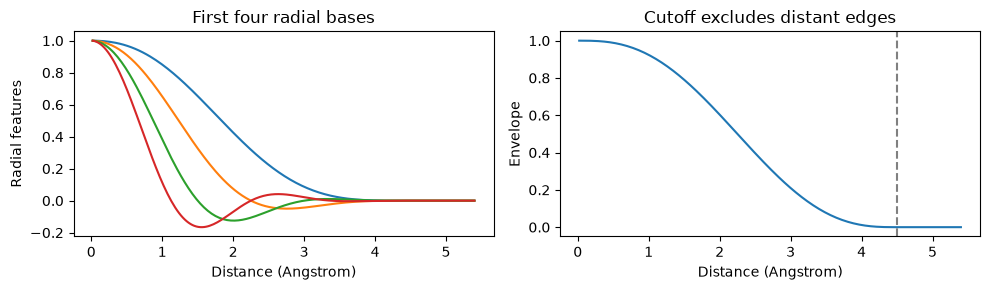

In [60]:
distance_grid = torch.linspace(0.02, config.conv_cutoff * 1.2, 200)
vectors_grid = torch.stack(
    [distance_grid, torch.zeros_like(distance_grid), torch.zeros_like(distance_grid)], -1
)
radial_grid, sh_grid, envelope_grid = geometry(
    vectors_grid, config.conv_cutoff, config.num_rbf, config.lmax
)
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].plot(distance_grid, radial_grid[:, :4])
axes[0].set(
    xlabel="Distance (Angstrom)", ylabel="Radial features", title="First four radial bases"
)
axes[1].plot(distance_grid, envelope_grid)
axes[1].axvline(config.conv_cutoff, color="gray", linestyle="--")
axes[1].set(
    xlabel="Distance (Angstrom)", ylabel="Envelope", title="Cutoff excludes distant edges"
)
fig.tight_layout()
plt.show()


### 신경망을 통과할 때 shape 관찰하기

`forward hook`은 모델 내부 값을 바꾸지 않고 각 module이 반환한 tensor의 크기를 관찰하는 PyTorch 기능입니다.
동일 module이 여러 번 호출되면 마지막 shape를 표시합니다. 이 셀의 랜덤 초기 모델은 아직 학습하지 않았습니다.

In [61]:
torch.manual_seed(SEED)
inspection_model = IFCModel(config).double()
shape_trace = {}
handles = []


def record_shape(name):
    def hook(module, inputs, output):
        shape_trace[name] = (
            tuple(output.shape)
            if isinstance(output, torch.Tensor)
            else type(output).__name__
        )

    return hook


for name, module in inspection_model.named_modules():
    if (
        name
        in {
            "backbone.embedding",
            "backbone.embed",
            "backbone.pair_init",
            "backbone.readout",
        }
        or name.startswith("backbone.layers.")
        and name.count(".") == 2
    ):
        handles.append(module.register_forward_hook(record_shape(name)))
try:
    with torch.no_grad():
        group_fc, image_fc = inspection_model(example, return_images=True)
finally:
    for handle in handles:
        handle.remove()
for name, shape in shape_trace.items():
    print(f"{name:30s} -> {shape}")
print("group IFC2:", tuple(group_fc.shape), "image IFC2:", tuple(image_fc.shape))
print("물리 잔차:", diagnostics(group_fc, example))
print("숨은 irreps:", inspection_model.backbone.ir)
print("파라미터 수:", sum(p.numel() for p in inspection_model.parameters()))


backbone.embedding             -> (3, 3)
backbone.embed                 -> (3, 51)
backbone.pair_init             -> (60, 51)
backbone.layers.0              -> (3, 51)
backbone.layers.1              -> (3, 51)
backbone.readout               -> (60, 9)
group IFC2: (51, 3, 3) image IFC2: (60, 3, 3)
물리 잔차: {'reciprocity_error': 0.0, 'asr_error': 1.3877787807814457e-17, 'onsite_symmetry_error': 2.8189256484623115e-18}
숨은 irreps: 3x0e+3x1o+3x1e+3x2o+3x2e
파라미터 수: 19033


## 15. 실제 학습과 loss 곡선

이 셀은 구조별로 forward/backward를 수행하고 checkpoint를 저장합니다.
`train_loss`에는 reciprocal 단계부터 추가 loss가 들어가지만 `validation_loss`는 계속 FC loss입니다.
따라서 stage 경계에서 두 곡선을 동일한 목적함수처럼 해석하지 마세요.

CPU 학습 시작


**최종 test 지표 — 합성 데이터**

{
  "fc_mae": 0.05725824872197546,
  "scaled_loss": 0.7407459928102158,
  "irrep_0_mae": 0.25895164118633984,
  "irrep_1_mae": 0.0009663263711263148,
  "irrep_2_mae": 0.015206156160827607,
  "dm_mae": 0.025172956321116966,
  "dm_model_mae": 0.025172956321116966,
  "cutoff_dm_mae": 2.2617215813394628e-17,
  "constraint_dm_shift": 5.671445770951333e-18,
  "target_constraint_fc_shift": 1.163663089876381e-17,
  "hermiticity_error": 3.469446951953614e-18,
  "target_hermiticity_error": 1.3985787785349405e-17,
  "reciprocity_error": 0.0,
  "asr_error": 7.45931094670027e-17,
  "onsite_symmetry_error": 1.3877787807814457e-17,
  "imaginary_modes": 1.0,
  "frequency_mae_thz": 4.1687359227169996,
  "target_imaginary_modes": 0.0,
  "imaginary_mode_mismatch": 0.037037037037037035,
  "rotation_error": 5.551115123125783e-17,
  "parameters": 19033,
  "training_seconds": 5.914108488999773,
  "peak_gpu_memory_bytes": null,
  "device": "cpu",
  "epochs": 8,
  "reciprocal_epochs": 2,
  "seed": 17,
  "data_

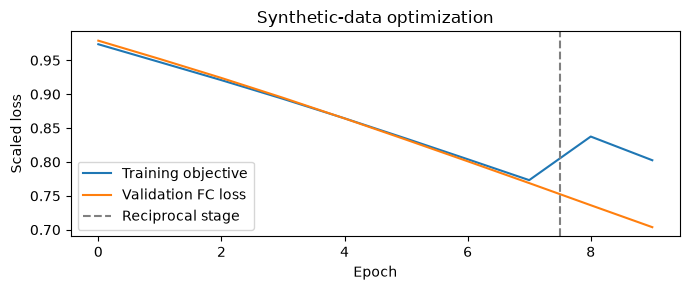

In [62]:
print("CPU 학습 시작", flush=True)
training_metrics = train(
    DATA_DIR,
    TRAIN_DIR,
    config,
    epochs=EPOCHS,
    reciprocal_epochs=RECIPROCAL_EPOCHS,
    seed=SEED,
    device=DEVICE,
)
display(Markdown("**최종 test 지표 — 합성 데이터**"))
print(json.dumps(training_metrics, indent=2))
history = json.loads((TRAIN_DIR / "history.json").read_text())
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(
    [x["epoch"] for x in history],
    [x["train_loss"] for x in history],
    label="Training objective",
)
ax.plot(
    [x["epoch"] for x in history],
    [x["validation_loss"] for x in history],
    label="Validation FC loss",
)
if RECIPROCAL_EPOCHS:
    ax.axvline(EPOCHS - 0.5, color="gray", linestyle="--", label="Reciprocal stage")
ax.set(xlabel="Epoch", ylabel="Scaled loss", title="Synthetic-data optimization")
ax.legend()
fig.tight_layout()
plt.show()


## 16. Checkpoint 복원 → 구조만으로 예측 → compact FC 출력

새 모델 객체를 만든 뒤 checkpoint weight를 복원합니다. 정답 FC를 참조하지 않는 `labels=False` 경로로 추론합니다.
`image_fc`는 [M,3,3], `compact_pair_fc`는 [P,3,3]이며 group별 합산 관계를 아래에서 다시 확인합니다.

In [63]:
checkpoint_path = TRAIN_DIR / "best.pt"
loaded_model, checkpoint_info = load_checkpoint(checkpoint_path)
print("선택된 epoch:", checkpoint_info["epoch"])
print("분할:", checkpoint_info["split"])
prediction_dir = RUN_DIR / "prediction"
prediction_report = predict(checkpoint_path, DATA_DIR / "synthetic_000", prediction_dir)
print("추론 물리 잔차:", prediction_report)
with np.load(prediction_dir / "pairs.npz") as pairs_file:
    image_values = torch.from_numpy(pairs_file["image_fc"])
    group_values = torch.from_numpy(pairs_file["compact_pair_fc"])
    owners = torch.from_numpy(pairs_file["image_owner"])
    torch.testing.assert_close(
        scatter(image_values, owners, len(group_values)), group_values
    )
    print("image → compact 합산 검증 통과")
print("Phonopy 입력:", prediction_dir / "FORCE_CONSTANTS")
print("출력 첫 group tensor (eV/Å²):\n", group_values[0])


선택된 epoch: 9
분할: {'train': ['synthetic_004', 'synthetic_001', 'synthetic_005', 'synthetic_002'], 'validation': ['synthetic_003'], 'test': ['synthetic_000']}


추론 물리 잔차: {'reciprocity_error': 0.0, 'asr_error': 7.45931094670027e-17, 'onsite_symmetry_error': 1.3877787807814457e-17}
image → compact 합산 검증 통과
Phonopy 입력: /tmp/ifc2_notebook_standalone_ktwjxd4h/ifc2_notebook_runs/20261025T130127Z_3a028e91/prediction/FORCE_CONSTANTS
출력 첫 group tensor (eV/Å²):
 tensor([[ 1.7632e-03,  8.8986e-05, -7.5243e-05],
        [ 8.8986e-05,  3.3401e-03, -2.1115e-05],
        [-7.5243e-05, -2.1115e-05,  3.2781e-03]])


### 같은 구조·q-path에서 reference와 예측 포논 비교

검정 실선은 합성 reference, 빨간 점선은 GNN 예측입니다. 충분히 학습하지 않으면 차이가 큰 것이 정상이며
그 차이를 숨기지 않습니다. 음의 signed frequency는 imaginary mode입니다.
아래 path는 Γ–(0.5,0,0)–(0.5,0.5,0)–Γ의 예시 경로입니다. 실제 물질의 고대칭 path를 쓰려면 `qfile`을 지정하세요.

{
  "frequency_mae_thz": 4.295478598365433,
  "nac": false,
  "nac_parameters_present": false,
  "target_raw_hermiticity_error": 1.962615573354719e-17,
  "predicted_raw_hermiticity_error": 3.469446951953614e-18,
  "path": "illustrative Gamma-(.5,0,0)-(.5,.5,0)-Gamma",
  "reference": "provided FORCE_CONSTANTS (provenance determined by input dataset)",
  "target_requires_hermitian_repair": false
}


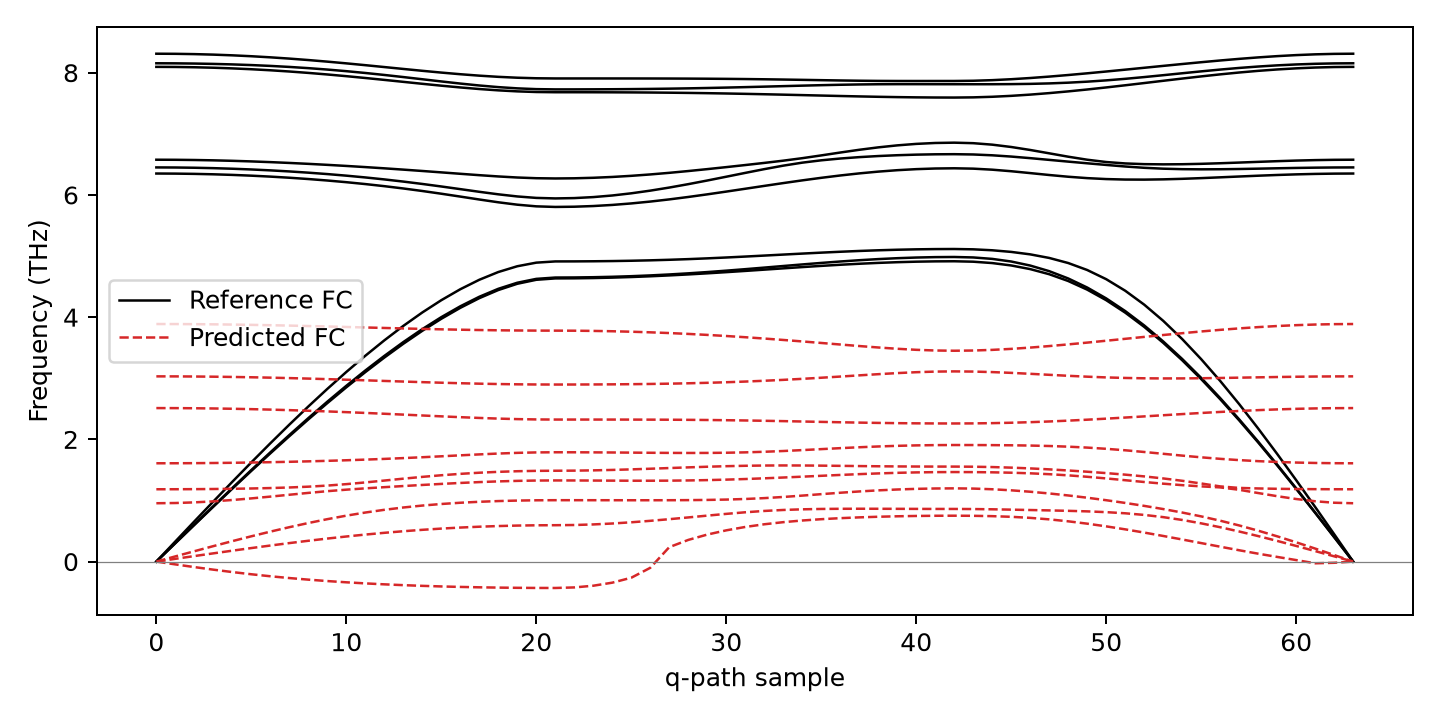

In [64]:
phonon_dir = RUN_DIR / "phonons"
phonon_report = compare(checkpoint_path, DATA_DIR / "synthetic_000", phonon_dir, nac=False)
print(json.dumps(phonon_report, indent=2))
display(Image(filename=str(phonon_dir / "dispersion.png")))


## 17. A–F ablation과 대조군

A: 독립 symmetric/skew 기본 모델 → B: correlation → C: attention → D: 둘 다 →
E: enhanced pair fusion → F: physics residual. E_shared, E_attention_only도 함께 비교합니다.
A는 기존 notebook의 정확한 재현이 아니라 핵심 구성의 축소 재구현입니다.

**해석 제한:** 같은 epoch/width로도 parameter count가 다릅니다. 작은 합성 데이터와 단일 seed의 짧은 실험이므로
“최고 모델” 결론보다 어떤 경로가 실제 실행되며 어떤 오차가 기록되는지 확인하세요.
GPU memory는 CPU 실행에서는 null입니다. ablation 함수는 CPU 비교를 사용합니다.

In [65]:
def show_ablation_table(rows):
    headers = [
        "Model",
        "Parameters",
        "FC MAE",
        "1e MAE",
        "Frequency MAE (THz)",
        "Train time (s)",
    ]
    table = "| " + " | ".join(headers) + " |\n|" + "---|" * len(headers) + "\n"
    for row in rows:
        frequency = (
            "N/A" if row["frequency_mae_thz"] is None else f"{row['frequency_mae_thz']:.5f}"
        )
        table += f"| {row['model']} | {row['parameters']} | {row['fc_mae']:.6f} | {row['irrep_1_mae']:.7f} | {frequency} | {row['training_seconds']:.2f} |\n"
    display(Markdown(table))


ablation_results = []
if RUN_ABLATIONS:
    ablation_results = ablations(
        DATA_DIR,
        RUN_DIR / "ablation",
        epochs=ABLATION_EPOCHS,
        width=config.width,
        seed=SEED,
    )
    show_ablation_table(ablation_results)
    print("CSV:", RUN_DIR / "ablation" / "results.csv")
else:
    print("Ablation은 실행하지 않았습니다. RUN_ABLATIONS=True로 변경하면 계산합니다.")


A {"fc_mae": 0.06739850214509865, "scaled_loss": 1.06643974847725, "irrep_0_mae": 0.28525031195203127, "irrep_1_mae": 0.000919689303457463, "irrep_2_mae": 0.02494989603304503, "dm_mae": 0.028305402494398463, "dm_model_mae": 0.028305402494398463, "cutoff_dm_mae": 2.2617215813394628e-17, "constraint_dm_shift": 5.671445770951333e-18, "target_constraint_fc_shift": 1.163663089876381e-17, "hermiticity_error": 2.2351400383409363e-19, "target_hermiticity_error": 1.3985787785349405e-17, "reciprocity_error": 0.0, "asr_error": 6.938893903907228e-18, "onsite_symmetry_error": 8.673617379884035e-19, "imaginary_modes": 15.0, "frequency_mae_thz": 5.7485918982101305, "target_imaginary_modes": 0.0, "imaginary_mode_mismatch": 0.5555555555555556, "rotation_error": 1.3877787807814457e-17, "parameters": 27234, "training_seconds": 1.7401148450007895, "peak_gpu_memory_bytes": null, "device": "cpu", "epochs": 3, "reciprocal_epochs": 0, "seed": 17, "data_kind": "synthetic", "train_materials": 4, "validation_mat

B {"fc_mae": 0.06629770695250237, "scaled_loss": 1.020595885558585, "irrep_0_mae": 0.284297312984097, "irrep_1_mae": 0.0009196291382371333, "irrep_2_mae": 0.02316217750437391, "dm_mae": 0.028113525653399297, "dm_model_mae": 0.028113525653399297, "cutoff_dm_mae": 2.2617215813394628e-17, "constraint_dm_shift": 5.671445770951333e-18, "target_constraint_fc_shift": 1.163663089876381e-17, "hermiticity_error": 8.683141271781244e-19, "target_hermiticity_error": 1.3985787785349405e-17, "reciprocity_error": 0.0, "asr_error": 4.5102810375396984e-17, "onsite_symmetry_error": 6.938893903907228e-18, "imaginary_modes": 15.0, "frequency_mae_thz": 5.837303985523077, "target_imaginary_modes": 0.0, "imaginary_mode_mismatch": 0.5555555555555556, "rotation_error": 9.71445146547012e-17, "parameters": 32094, "training_seconds": 2.2881344469933538, "peak_gpu_memory_bytes": null, "device": "cpu", "epochs": 3, "reciprocal_epochs": 0, "seed": 17, "data_kind": "synthetic", "train_materials": 4, "validation_materi

C {"fc_mae": 0.0668153178433159, "scaled_loss": 1.0439801088980942, "irrep_0_mae": 0.2836760843278477, "irrep_1_mae": 0.0009292778947916177, "irrep_2_mae": 0.024396901718828405, "dm_mae": 0.028046059075691323, "dm_model_mae": 0.028046059075691326, "cutoff_dm_mae": 2.2617215813394628e-17, "constraint_dm_shift": 5.671445770951333e-18, "target_constraint_fc_shift": 1.163663089876381e-17, "hermiticity_error": 4.4702800766818725e-19, "target_hermiticity_error": 1.3985787785349405e-17, "reciprocity_error": 0.0, "asr_error": 2.7755575615628914e-17, "onsite_symmetry_error": 1.734723475976807e-18, "imaginary_modes": 15.0, "frequency_mae_thz": 5.757597019843852, "target_imaginary_modes": 0.0, "imaginary_mode_mismatch": 0.5555555555555556, "rotation_error": 3.642919299551295e-17, "parameters": 28166, "training_seconds": 1.9641372229962144, "peak_gpu_memory_bytes": null, "device": "cpu", "epochs": 3, "reciprocal_epochs": 0, "seed": 17, "data_kind": "synthetic", "train_materials": 4, "validation_ma

D {"fc_mae": 0.06719549902292847, "scaled_loss": 1.0678726206067937, "irrep_0_mae": 0.28448359077999774, "irrep_1_mae": 0.0009563876349355731, "irrep_2_mae": 0.02481805071254954, "dm_mae": 0.028241514545613102, "dm_model_mae": 0.028241514545613102, "cutoff_dm_mae": 2.2617215813394628e-17, "constraint_dm_shift": 5.671445770951333e-18, "target_constraint_fc_shift": 1.163663089876381e-17, "hermiticity_error": 3.2974721750313767e-19, "target_hermiticity_error": 1.3985787785349405e-17, "reciprocity_error": 0.0, "asr_error": 6.938893903907228e-18, "onsite_symmetry_error": 3.469446951953614e-18, "imaginary_modes": 8.0, "frequency_mae_thz": 5.528591511835487, "target_imaginary_modes": 0.0, "imaginary_mode_mismatch": 0.2962962962962963, "rotation_error": 5.204170427930421e-17, "parameters": 33026, "training_seconds": 2.7712355550029315, "peak_gpu_memory_bytes": null, "device": "cpu", "epochs": 3, "reciprocal_epochs": 0, "seed": 17, "data_kind": "synthetic", "train_materials": 4, "validation_mat

E {"fc_mae": 0.06567407348750838, "scaled_loss": 0.97324478876089, "irrep_0_mae": 0.2843815597974935, "irrep_1_mae": 0.0009307185017636531, "irrep_2_mae": 0.021978574138284586, "dm_mae": 0.02811558174584041, "dm_model_mae": 0.028115581745840414, "cutoff_dm_mae": 2.2617215813394628e-17, "constraint_dm_shift": 5.671445770951333e-18, "target_constraint_fc_shift": 1.163663089876381e-17, "hermiticity_error": 5.42101353119013e-19, "target_hermiticity_error": 1.3985787785349405e-17, "reciprocity_error": 0.0, "asr_error": 9.540979117872439e-18, "onsite_symmetry_error": 6.071532165918825e-18, "imaginary_modes": 10.0, "frequency_mae_thz": 5.595251317745839, "target_imaginary_modes": 0.0, "imaginary_mode_mismatch": 0.37037037037037035, "rotation_error": 2.7755575615628914e-17, "parameters": 38066, "training_seconds": 3.5553344969957834, "peak_gpu_memory_bytes": null, "device": "cpu", "epochs": 3, "reciprocal_epochs": 0, "seed": 17, "data_kind": "synthetic", "train_materials": 4, "validation_mater

F {"fc_mae": 0.06535872260307407, "scaled_loss": 1.260338319486587, "irrep_0_mae": 0.26276616812062215, "irrep_1_mae": 0.0009181013773907542, "irrep_2_mae": 0.02908741239961763, "dm_mae": 0.02629247175548031, "dm_model_mae": 0.02629247175548031, "cutoff_dm_mae": 2.2617215813394628e-17, "constraint_dm_shift": 5.671445770951333e-18, "target_constraint_fc_shift": 1.163663089876381e-17, "hermiticity_error": 1.3011072068652112e-18, "target_hermiticity_error": 1.3985787785349405e-17, "reciprocity_error": 0.0, "asr_error": 3.859759734048396e-17, "onsite_symmetry_error": 1.5612511283791264e-17, "imaginary_modes": 1.0, "frequency_mae_thz": 4.218110514237081, "target_imaginary_modes": 0.0, "imaginary_mode_mismatch": 0.037037037037037035, "rotation_error": 6.938893903907228e-17, "parameters": 38172, "training_seconds": 3.9423434310010634, "peak_gpu_memory_bytes": null, "device": "cpu", "epochs": 3, "reciprocal_epochs": 0, "seed": 17, "data_kind": "synthetic", "train_materials": 4, "validation_mat

| Model | Parameters | FC MAE | 1e MAE | Frequency MAE (THz) | Train time (s) |
|---|---|---|---|---|---|
| A | 27234 | 0.067399 | 0.0009197 | 5.74859 | 1.74 |
| B | 32094 | 0.066298 | 0.0009196 | 5.83730 | 2.29 |
| C | 28166 | 0.066815 | 0.0009293 | 5.75760 | 1.96 |
| D | 33026 | 0.067195 | 0.0009564 | 5.52859 | 2.77 |
| E | 38066 | 0.065674 | 0.0009307 | 5.59525 | 3.56 |
| F | 38172 | 0.065359 | 0.0009181 | 4.21811 | 3.94 |
| E_shared | 19033 | 0.065678 | 0.0009422 | 5.59494 | 1.78 |
| E_attention_only | 38066 | 0.065648 | 0.0009480 | 5.58891 | 3.53 |


CSV: /tmp/ifc2_notebook_standalone_ktwjxd4h/ifc2_notebook_runs/20261025T130127Z_3a028e91/ablation/results.csv


<a id="real"></a>
## 18. 실제 데이터와 내 구조에 적용하기

아래 셀은 기본적으로 실행하지 않습니다. `REAL_DATA_ROOT`에 실제 자료 경로를 넣고
`RUN_REAL_TRAIN=True`로 바꿔 사용합니다. 폴더에는 material마다 phonopy.yaml/FORCE_CONSTANTS가 있어야 합니다.
단위(Å, amu, eV/Å²), 원래 DFT 계산 방법과 parent-material split을 확인하세요.

```text
my_dataset/
  material_A/phonopy.yaml
  material_A/FORCE_CONSTANTS
  material_B/phonopy.yaml
  material_B/FORCE_CONSTANTS
  ...
```

split은 JSON 또는 dictionary로 `{"train":["material_A"],"validation":["material_B"],"test":["material_C"]}`처럼 줍니다.
경로 이름만 다른 동일 물질을 여러 split에 넣지 마세요. 최소 3개의 독립 material group이 필요합니다.

CIF/POSCAR 구조만 있다면 `predict(checkpoint, 'structure.cif', output, structure=True, supercell=(3,3,3))`로 예측합니다.
합성 checkpoint를 실제 조성에 적용한 결과를 검증된 물성으로 신뢰해서는 안 됩니다.

In [66]:
RUN_REAL_TRAIN = False
REAL_DATA_ROOT = None  # 예: Path("/content/my_dataset")
REAL_SPLIT = (
    None  # 실제 연구에는 parent-material 기준 dictionary를 제공하는 것을 권장합니다.
)

if RUN_REAL_TRAIN:
    if REAL_DATA_ROOT is None or not Path(REAL_DATA_ROOT).is_dir():
        raise ValueError("실제 데이터 폴더 REAL_DATA_ROOT를 먼저 지정하세요.")
    real_audit = audit_dataset(
        REAL_DATA_ROOT, RUN_DIR / "real_audit.json", config.conv_cutoff, config.pair_cutoff
    )
    print(json.dumps(real_audit, indent=2))
    # 큰 raw 잔차가 있으면 아래 train을 진행하기 전에 데이터 원인을 조사하세요.
    real_metrics = train(
        REAL_DATA_ROOT,
        RUN_DIR / "real_training",
        config,
        epochs=100,
        seed=SEED,
        device=DEVICE,
        split=REAL_SPLIT,
    )
    print(json.dumps(real_metrics, indent=2))
else:
    print("실제 데이터 학습: 미실행 (기본 실습은 합성 데이터입니다.)")


실제 데이터 학습: 미실행 (기본 실습은 합성 데이터입니다.)


## 19. 부록: 기존 CLI 기능도 단일 노트북에 포함

명령줄 dispatcher 전체를 포함하되 notebook kernel의 argv를 읽지 않도록 호출자가 인자 list를 제공할 수 있게 했습니다. 기본 실행에는 필요하지 않습니다.

### `ifc2_cli_main`

기존 CLI 기능도 노트북에서 사용할 수 있게 이름을 바꾸고 argv 인자를 추가했습니다. 예: ifc2_cli_main(['synthetic','--out',str(RUN_DIR/'cli_data')]). 아래 본문은 더 읽기 쉬운 함수 직접 호출을 사용합니다. 노트북 kernel의 자체 argv와 혼동되지 않도록 인자 list를 명시하세요.

In [67]:
def ifc2_cli_main(argv=None):
    torch.set_default_dtype(torch.float64)
    torch.set_num_threads(1)
    parser = argparse.ArgumentParser(
        description="Equivariant direct IFC2 research prototype"
    )
    sub = parser.add_subparsers(dest="command", required=True)
    p = sub.add_parser("synthetic")
    p.add_argument("--out", required=True)
    p.add_argument("--count", type=int, default=6)
    p = sub.add_parser("audit")
    p.add_argument("--data", required=True)
    p.add_argument("--out", required=True)
    p.add_argument("--conv-cutoff", type=float, default=4.5)
    p.add_argument("--pair-cutoff", type=float, default=5.5)
    p = sub.add_parser("train")
    p.add_argument("--data", required=True)
    p.add_argument("--out", required=True)
    p.add_argument("--config")
    p.add_argument("--epochs", type=int, default=10)
    p.add_argument("--reciprocal-epochs", type=int, default=0)
    p.add_argument("--seed", type=int, default=17)
    p.add_argument("--device", default="cpu")
    p.add_argument("--split")
    p = sub.add_parser("ablate")
    p.add_argument("--data", required=True)
    p.add_argument("--out", required=True)
    p.add_argument("--epochs", type=int, default=5)
    p.add_argument("--width", type=int, default=3)
    p.add_argument("--seed", type=int, default=17)
    for command in ["predict", "compare"]:
        p = sub.add_parser(command)
        p.add_argument("--checkpoint", required=True)
        p.add_argument("--material", required=True)
        p.add_argument("--out", required=True)
        if command == "compare":
            p.add_argument("--nac", action="store_true")
            p.add_argument("--qpoints")
        else:
            p.add_argument("--structure", action="store_true")
            p.add_argument("--supercell", type=int, nargs=3, default=[2, 2, 2])
    args = parser.parse_args(argv)
    if args.command == "synthetic":
        make_dataset(args.out, args.count)
        print("Created explicitly synthetic fixtures")
    elif args.command == "audit":
        print(
            json.dumps(
                audit_dataset(args.data, args.out, args.conv_cutoff, args.pair_cutoff),
                indent=2,
            )
        )
    elif args.command == "train":
        cfg = ModelConfig(
            **(yaml.safe_load(Path(args.config).read_text()) if args.config else {})
        )
        split = json.loads(Path(args.split).read_text()) if args.split else None
        print(
            json.dumps(
                train(
                    args.data,
                    args.out,
                    cfg,
                    args.epochs,
                    args.seed,
                    device=args.device,
                    reciprocal_epochs=args.reciprocal_epochs,
                    split=split,
                ),
                indent=2,
            )
        )
    elif args.command == "ablate":
        ablations(args.data, args.out, args.epochs, args.width, args.seed)
    elif args.command == "predict":
        print(
            json.dumps(
                predict(
                    args.checkpoint, args.material, args.out, args.structure, args.supercell
                ),
                indent=2,
            )
        )
    else:
        print(
            json.dumps(
                compare(args.checkpoint, args.material, args.out, args.nac, args.qpoints),
                indent=2,
            )
        )


## 20. 부록: Zenodo metadata 및 검증 다운로드

사용자 제공 기록은 https://zenodo.org/records/20196565 입니다. 아래 함수는 네트워크 접근이 허용된 환경에서 사용합니다. 파일 목록·용량·라이선스를 먼저 확인하고 다운로드할 정확한 이름을 지정하세요.

### `fetch_zenodo_cli`

Zenodo API metadata를 먼저 표시하고 정확히 지정한 파일만 size cap 및 checksum 검사 후 저장합니다. 자동 압축해제나 코드 실행은 없습니다. 기본 Run All에서는 호출하지 않습니다. 네트워크 허용과 실제 metadata 확인이 필요하며, 이전 환경의 403 차단을 성공한 다운로드처럼 보고하지 않습니다.

In [68]:
def fetch_zenodo_cli(argv=None):
    p = argparse.ArgumentParser()
    p.add_argument("--record", default="20196565")
    p.add_argument("--file", help="Exact filename from the listing")
    p.add_argument("--out", default="data/downloads")
    p.add_argument("--max-bytes", type=int, default=512 * 1024 * 1024)
    a = p.parse_args(argv)
    if not a.record.isdigit():
        raise ValueError("Record must be numeric")
    with urllib.request.urlopen(
        f"https://zenodo.org/api/records/{a.record}", timeout=60
    ) as r:
        record = json.load(r)
    print(
        json.dumps(
            {
                "title": record["metadata"].get("title"),
                "license": record["metadata"].get("license"),
                "files": [
                    {k: f.get(k) for k in ["key", "size", "checksum"]}
                    for f in record.get("files", [])
                ],
            },
            indent=2,
        )
    )
    if not a.file:
        return
    matches = [f for f in record["files"] if f["key"] == a.file]
    if len(matches) != 1:
        raise ValueError("Filename not unique or missing")
    f = matches[0]
    if f["size"] > a.max_bytes:
        raise ValueError("File exceeds --max-bytes; inspect storage before increasing")
    name = Path(a.file).name
    if name != a.file:
        raise ValueError("Only plain filenames accepted")
    root = Path(a.out)
    root.mkdir(parents=True, exist_ok=True)
    target = root / name
    partial = root / (name + ".part")
    if target.exists() or partial.exists():
        raise FileExistsError(target)
    algorithm, expected = f["checksum"].split(":", 1)
    digest = hashlib.new(algorithm)
    url = f["links"].get("self") or f["links"].get("content")
    if not url.startswith("https://zenodo.org/"):
        raise ValueError("Unexpected download destination")
    try:
        size = 0
        with urllib.request.urlopen(url, timeout=60) as response, partial.open(
            "xb"
        ) as output:
            while block := response.read(1024 * 1024):
                size += len(block)
                if size > a.max_bytes:
                    raise ValueError("Download size cap exceeded")
                digest.update(block)
                output.write(block)
        if size != f["size"] or digest.hexdigest() != expected:
            raise ValueError("Size/checksum mismatch")
        partial.rename(target)
        (root / (name + ".provenance.json")).write_text(json.dumps(record, indent=2))
        print(f"Verified {target}: {algorithm}:{expected}")
    except BaseException:
        partial.unlink(missing_ok=True)
        raise


In [69]:
RUN_ZENODO_LIST = False
if RUN_ZENODO_LIST:
    fetch_zenodo_cli(["--record", "20196565"])
else:
    print("Zenodo 네트워크 요청: 미실행. metadata를 확인하려면 RUN_ZENODO_LIST=True.")
# metadata 확인 후 실제 파일 이름을 넣어 호출하세요:
# fetch_zenodo_cli(["--record", "20196565", "--file", "ACTUAL_FILENAME",
#                   "--out", str(RUN_DIR / "downloads")])


Zenodo 네트워크 요청: 미실행. metadata를 확인하려면 RUN_ZENODO_LIST=True.


## 21. 결과 위치와 다음 연구 질문

- 실제 실행한 test 결과: `test_results.json`
- checkpoint/학습곡선 원자료: `training/best.pt`, `training/history.json`
- test metrics: `training/metrics.json`
- FC 출력: `prediction/FORCE_CONSTANTS`, `prediction/pairs.npz`
- 포논 비교: `phonons/dispersion.png`, `phonons/dispersion.npz`
- 비교 실험: `ablation/results.csv`, `ablation/results.json` (옵션을 켠 경우)

### 아직 보장하지 않는 것

1. **rotational sum rule / 에너지 적분가능성 / 안정성**: 좌표 O(3) 등변성·ASR·reciprocity와 별개입니다.
2. **full MACE correlation**: 재귀 projected tensor product이며 complete symmetric basis와 다릅니다.
3. **compact alias 해소**: 여러 image의 합만 알려진 경우 개별 image IFC는 식별되지 않습니다.
4. **polar/2D/magnetic universal 물리**: Born/dielectric은 공급받아 비교하고, 2D NAC·magnetic-state 입력은 없습니다.
5. **DFT 성능과 신규성**: 실제 데이터, parameter-matched multi-seed 비교, 충분한 q-mesh와 문헌 검토가 필요합니다.

### 공개 구현과 라이선스

개념/수치 기준은 HamGNN(GPL-3.0-only), MACE(MIT), e3nn(MIT), Phonopy(BSD-3-Clause)를 조사했습니다.
HamGNN/MACE 소스를 이 노트북에 복사하거나 import하지 않았고, e3nn/Phonopy의 공개 API를 사용합니다.
[HamGNN](https://github.com/QuantumLab-ZY/HamGNN) · [MACE](https://github.com/ACEsuit/mace) ·
[e3nn](https://github.com/e3nn/e3nn) · [Phonopy](https://github.com/phonopy/phonopy).
논문 본문은 이전 환경에서 접근 제한으로 확인하지 못했으므로 문헌 전체 검토 완료로 표시하지 않습니다.

저장된 출력은 이 노트북의 새 CPU 실행으로 생성됩니다. 본문 설정과 출력의 값이 다르면 kernel을 재시작하고 전체를 다시 실행하세요.

In [70]:
# 이 파일이 설치된 ifc2 패키지를 이용하지 않고 직접 정의한 코드만 사용했는지 확인합니다.
assert not any(name == "ifc2" or name.startswith("ifc2.") for name in sys.modules)
notebook_summary = {
    "tests_passed": len(notebook_test_results),
    "synthetic_training": training_metrics,
    "phonon_comparison": phonon_report,
    "ablation_models_run": [row["model"] for row in ablation_results],
    "real_data_training_run": RUN_REAL_TRAIN,
    "zenodo_listing_run": RUN_ZENODO_LIST,
    "local_ifc2_package_imported": False,
}
(RUN_DIR / "notebook_summary.json").write_text(json.dumps(notebook_summary, indent=2))
print("노트북 실행 완료:", RUN_DIR)
print("테스트:", len(notebook_test_results), "passed")
print("이번에 실행한 ablation:", notebook_summary["ablation_models_run"])
print("이 결과는 합성 데이터입니다.")


노트북 실행 완료: /tmp/ifc2_notebook_standalone_ktwjxd4h/ifc2_notebook_runs/20261025T130127Z_3a028e91
테스트: 17 passed
이번에 실행한 ablation: ['A', 'B', 'C', 'D', 'E', 'F', 'E_shared', 'E_attention_only']
이 결과는 합성 데이터입니다.
